# News Topic Classification

**Research question**

How do **TF-IDF + Logistic Regression** and **frozen MiniLM + Logistic Regression** compare on
English AG News headlines, especially those with six words or fewer?

The four categories are **World · Sports · Business · Science and Technology**.
The models use headlines as input. Descriptions are used only to group duplicate records.

**Presenting the results**

Open this `.ipynb` file from the Jupyter Notebook file browser. The tables and charts are saved
from a previous run and are ready to present as soon as the notebook opens. Follow the numbered
sections from data preparation through both models, the final comparison, and error analysis.

To reproduce the results, use a fresh Python environment with compatible packages and run the
cells in order. The first full run needs internet access for dependencies, AG News, and the
MiniLM encoder. A GPU can speed up embedding generation.

**Quick live demo**

Open the repository’s `index.html` in a browser. It uses the saved classifiers.
TF-IDF runs offline, and MiniLM downloads its encoder on first use.
Section 08 runs the demo inside the notebook with the models fitted in the current session.

## 01 · Setup

Install the pinned package versions, prepare the folders, and set the random seed.
The setup cell prints the directory where the notebook writes its outputs.

In [ ]:
# Install the project’s pinned dependencies
import importlib.metadata
import subprocess
import sys

REQUIRED = {"ipywidgets": "8.1.7", "numpy": "2.3.5", "pandas": "2.2.3", "scikit-learn": "1.8.0", "matplotlib": "3.10.8", "threadpoolctl": "3.6.0", "sentence-transformers": "4.1.0", "transformers": "4.51.3", "huggingface-hub": "0.30.2", "tokenizers": "0.21.4", "safetensors": "0.5.3"}
# Preserve an existing compatible Colab PyTorch installation and accelerator stack.
# The verified CPU reference uses torch 2.6.0+cpu. Actual versions are recorded.
try:
    torch_version = importlib.metadata.version("torch")
except importlib.metadata.PackageNotFoundError:
    torch_version = None
if torch_version is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "torch==2.6.0", "--index-url", "https://download.pytorch.org/whl/cpu"])
else:
    version_parts = tuple(int(x) for x in torch_version.split("+")[0].split(".")[:2])
    if not (2, 6) <= version_parts < (3, 0):
        raise RuntimeError("Use a fresh runtime with PyTorch >=2.6 and <3. The verified CPU reference is 2.6.0.")
missing = []
for package, version in REQUIRED.items():
    try:
        installed = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        missing.append(f"{package}=={version}")
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
print("Required package versions:", REQUIRED)

In [ ]:
# Create data and results folders
from pathlib import Path
import random
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd()
if cwd.name == "notebooks":
    ROOT = cwd.parent
elif (cwd / "src/data_pipeline.py").exists():
    ROOT = cwd
else:
    ROOT = cwd / "news_topic_classification"
for folder in ["data/raw", "data/processed", "results/figures"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
print("Output directory:", ROOT)

In [ ]:
# @title Import data tools and set experiment constants
from collections import Counter, defaultdict
import hashlib
import html
import importlib.metadata
import itertools
import json
import math
from pathlib import Path
import platform
import re
import tarfile
import unicodedata
import urllib.request

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42
SHORT_MAX_WORDS = 6
NEAR_JACCARD_PERCENT = 85
NEAR_MIN_UNIQUE_TOKENS = 4
DATA_URL = "https://drive.google.com/uc?export=download&id=0Bz8a_Dbh9QhbUDNpeUdjb0wxRms"
ARCHIVE_SHA256 = "4e2fc37d369e6e317a8b62d0d2f11d379f8c3dde60c07c35a46b069a246498ad"
LABELS = {1: "World", 2: "Sports", 3: "Business", 4: "Science and Technology"}

In [ ]:
# @title Define SHA-256 and JSON utilities
def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def write_json(path, value):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")

In [ ]:
# Set the seed and verify installed versions
random.seed(SEED)
np.random.seed(SEED)
assert {p: importlib.metadata.version(p) for p in REQUIRED} == REQUIRED

## 02 · Data inspection

**AG News v3** contains 120,000 official training records and 7,600 official test records.
Each record has a label, a headline, and a description.
Verify the source archive's checksum and inspect the original class counts before preprocessing.

In [ ]:
# @title Download and check the original archive
def acquire_data(root):
    """Download the original author archive and enforce its measured checksum."""
    raw = Path(root) / "data/raw"
    raw.mkdir(parents=True, exist_ok=True)
    archive = raw / "ag_news_csv.tar.gz"
    if not archive.exists():
        temporary = archive.with_suffix(".download")
        endpoints = [DATA_URL,
                     "https://drive.usercontent.google.com/download?id=0Bz8a_Dbh9QhbUDNpeUdjb0wxRms&export=download&confirm=t"]
        errors = []
        for attempt, endpoint in enumerate(endpoints, start=1):
            try:
                with urllib.request.urlopen(endpoint, timeout=90) as response, temporary.open("wb") as out:
                    while chunk := response.read(1024 * 1024):
                        out.write(chunk)
                if sha256_file(temporary) != ARCHIVE_SHA256:
                    raise ValueError("Incomplete or changed archive: checksum mismatch.")
                temporary.replace(archive)
                break
            except (OSError, ValueError) as error:
                errors.append(f"attempt {attempt}: {type(error).__name__}")
                print(f"Download attempt {attempt} failed; only a checksum-verified original file will be accepted.")
            finally:
                temporary.unlink(missing_ok=True)
        if not archive.exists():
            raise RuntimeError("Original AG News download failed (" + "; ".join(errors) +
                               "). Retry acquisition or place the verified author archive in data/raw/ag_news_csv.tar.gz.")
    if sha256_file(archive) != ARCHIVE_SHA256:
        raise ValueError("Cached archive checksum mismatch. Remove the cache and download again.")
    # Extract only four explicitly allowed files; never trust archive paths.
    with tarfile.open(archive, "r:gz") as tar:
        for name in ["train.csv", "test.csv", "classes.txt", "readme.txt"]:
            source = tar.extractfile(f"ag_news_csv/{name}")
            if source is None:
                raise ValueError(f"Missing archive member: {name}")
            (raw / name).write_bytes(source.read())
    manifest = {
        "source_url": DATA_URL,
        "source_repository": "https://github.com/zhangxiangxiao/Crepe",
        "version": "3; archive README updated 2015-09-09",
        "archive_sha256": ARCHIVE_SHA256,
        "files_sha256": {name: sha256_file(raw / name) for name in
                         ["train.csv", "test.csv", "classes.txt", "readme.txt"]},
        "features": "Title only. Description is retained solely for duplicate grouping.",
        "usage_note": "Archive README describes research and other non-commercial activity; no blanket open-data license is assumed.",
    }
    write_json(Path(root) / "results/source_manifest.json", manifest)
    return manifest

In [ ]:
# @title Read the two official CSV files and assign record IDs
def load_data(root):
    frames = []
    for pool, expected in [("train", 120000), ("test", 7600)]:
        df = pd.read_csv(Path(root) / f"data/raw/{pool}.csv", header=None,
                         names=["label", "title", "description"], keep_default_na=False)
        assert len(df) == expected, (pool, len(df))
        assert set(df.label) == set(LABELS)
        assert df.label.value_counts().eq(expected // 4).all()
        df["source_pool"] = pool
        df["source_row"] = np.arange(len(df))
        df["record_id"] = [f"{pool}:{i:06d}" for i in range(len(df))]
        frames.append(df)
    return pd.concat(frames, ignore_index=True)

In [ ]:
# Load verified AG News and inspect class counts
source_manifest = acquire_data(ROOT)
raw = load_data(ROOT)
raw_counts = pd.crosstab(raw.source_pool, raw.label).rename(columns=LABELS)
display(raw_counts)
print("Archive SHA-256:", source_manifest["archive_sha256"])
print("Version:", source_manifest["version"])
print("Missing title fields:", int(raw.title.isna().sum()))
print("Empty raw titles:", int(raw.title.str.strip().eq("").sum()))

Archive SHA-256: 4e2fc37d369e6e317a8b62d0d2f11d379f8c3dde60c07c35a46b069a246498ad
Version: 3; archive README updated 2015-09-09
Missing title fields: 0
Empty raw titles: 0


label,World,Sports,Business,Science and Technology
source_pool,,,,
test,1900,1900,1900,1900
train,30000,30000,30000,30000


## 03 · Preprocessing

Decode HTML entities, normalize whitespace, and remove empty titles. A short headline contains
**1–6 words** after cleaning. Before splitting, group records with identical normalized titles
or identical normalized descriptions of at least 10 words. Also group titles with at least four
unique words each when their Jaccard similarity is 0.85 or higher. Transitive links stay in
the same group.

In [ ]:
# @title Clean titles and compute duplicate keys
def clean_text(value):
    """Minimal shared cleaning; leave case and punctuation for model tokenizers."""
    if value is None or pd.isna(value):
        return ""
    return " ".join(html.unescape(str(value)).split())


def audit_key(text):
    """More aggressive normalization for grouping only, never model features."""
    value = unicodedata.normalize("NFKC", text).casefold()
    return " ".join(re.findall(r"\w+", value, flags=re.UNICODE))


def clean_data(raw):
    data = raw.copy()
    data["text"] = data.title.map(clean_text)
    empty = data.text.eq("")
    removed = data.loc[empty, ["record_id", "source_pool", "title"]].copy()
    data = data.loc[~empty].reset_index(drop=True)
    data["word_count"] = data.text.str.split().str.len()
    data["is_short"] = data.word_count.between(1, SHORT_MAX_WORDS)
    data["title_key"] = data.text.map(audit_key)
    # Non-empty punctuation-only text must not collapse with unrelated punctuation.
    blank_keys = data.title_key.eq("")
    data.loc[blank_keys, "title_key"] = data.loc[blank_keys, "text"].str.casefold()
    data["description_key"] = data.description.map(clean_text).map(audit_key)
    return data, removed

In [ ]:
# @title Merge linked records into groups
class UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))

    def find(self, x):
        while x != self.parent[x]:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x

    def union(self, a, b):
        a, b = self.find(a), self.find(b)
        if a != b:
            self.parent[max(a, b)] = min(a, b)

In [ ]:
# @title Find exact and near-duplicate groups
def group_related(data):
    """Group exact keys and high-overlap title token sets without fitting features.

    Prefix filtering finds all pairs meeting the declared token-set Jaccard
    rule. It does not detect every paraphrase or every story about one event.
    Test labels are not consulted during this administrative grouping.
    """
    uf = UnionFind(len(data))
    for column in ["title_key", "description_key"]:
        first = {}
        for i, key in enumerate(data[column]):
            if not key or (column == "description_key" and len(key.split()) < 10):
                continue
            if key in first:
                uf.union(i, first[key])
            else:
                first[key] = i

    # One representative per token set avoids redundant pair comparisons.
    representatives = {}
    for i, key in enumerate(data.title_key):
        tokens = frozenset(key.split())
        if len(tokens) < NEAR_MIN_UNIQUE_TOKENS:
            continue
        if tokens in representatives:
            uf.union(i, representatives[tokens])
        else:
            representatives[tokens] = i
    frequencies = Counter(token for tokens in representatives for token in tokens)
    ordered = sorted(representatives, key=lambda x: (len(x), tuple(sorted(x))))
    postings = defaultdict(list)
    pairs = []
    comparisons = 0
    for position, tokens in enumerate(ordered):
        i = representatives[tokens]
        n = len(tokens)
        min_length = (NEAR_JACCARD_PERCENT * n + 99) // 100
        prefix_size = n - min_length + 1
        prefix = sorted(tokens, key=lambda t: (frequencies[t], t))[:prefix_size]
        candidates = set()
        for token in prefix:
            candidates.update(j for j in postings[token] if len(ordered[j]) >= min_length)
        for j in sorted(candidates):
            other = ordered[j]
            comparisons += 1
            intersection = len(tokens & other)
            union = n + len(other) - intersection
            if 100 * intersection >= NEAR_JACCARD_PERCENT * union:
                other_i = representatives[other]
                uf.union(i, other_i)
                pairs.append((i, other_i, intersection / union))
        for token in prefix:
            postings[token].append(position)

    result = data.copy()
    result["group_id"] = [f"g{uf.find(i):06d}" for i in range(len(data))]
    pair_df = pd.DataFrame(pairs, columns=["left_index", "right_index", "jaccard"])
    if len(pair_df):
        for side in ["left", "right"]:
            indices = pair_df[f"{side}_index"].to_numpy()
            pair_df[f"{side}_record_id"] = data.iloc[indices].record_id.to_numpy()
        pair_df = pair_df.drop(columns=["left_index", "right_index"])
    return result, pair_df, comparisons

### Create and verify the splits

Preserve the official test set and exclude linked records from the learning pool.
Within that pool, collapse repeated titles with the same label and keep conflicting labels.
Use the first fold of `StratifiedGroupKFold` with seed 42 to reserve about 10% for development
while keeping groups disjoint.

In [ ]:
# @title Define the grouped training and development split
def prepare_splits(data):
    """Keep official test rows; exclude entire linked groups from training pool."""
    test = data.loc[data.source_pool.eq("test")].copy()
    official_train = data.loc[data.source_pool.eq("train")].copy()
    touches_test = official_train.group_id.isin(set(test.group_id))
    overlap_removed = official_train.loc[touches_test].copy()
    eligible = official_train.loc[~touches_test].copy()
    # Collapse repeated same-label title keys in the learning pool only. Different
    # labels for the same title are retained together and disclosed as ambiguity.
    duplicate_mask = eligible.duplicated(["title_key", "label"], keep="first")
    duplicate_removed = eligible.loc[duplicate_mask].copy()
    eligible = eligible.loc[~duplicate_mask].reset_index(drop=True)
    splitter = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
    train_idx, dev_idx = next(splitter.split(eligible.text, eligible.label, eligible.group_id))
    splits = {"train": eligible.iloc[train_idx].copy(),
              "development": eligible.iloc[dev_idx].copy(), "test": test}
    for name, frame in splits.items():
        frame["split"] = name
    excluded = pd.concat([
        overlap_removed.assign(exclusion_reason="group_touches_official_test"),
        duplicate_removed.assign(exclusion_reason="same_title_same_label_in_learning_pool"),
    ], ignore_index=True)
    return splits, excluded

In [ ]:
# @title Check IDs, titles and groups for overlap
def verify_splits(splits, grouped, excluded):
    checks = []
    for a, b in itertools.combinations(splits, 2):
        for key in ["record_id", "title_key", "group_id"]:
            count = len(set(splits[a][key]) & set(splits[b][key]))
            checks.append({"pair": f"{a}/{b}", "key": key, "overlap": count})
            assert count == 0, (a, b, key, count)
    all_ids = [set(frame.record_id) for frame in splits.values()]
    assigned = set.union(*all_ids)
    excluded_ids = set(excluded.record_id)
    assert not assigned & excluded_ids
    assert assigned | excluded_ids == set(grouped.record_id)
    assert sum(map(len, all_ids)) + len(excluded_ids) == len(grouped)
    assert set(splits["test"].record_id) == set(grouped.loc[grouped.source_pool.eq("test"), "record_id"])
    for name, frame in splits.items():
        assert set(frame.label) == set(LABELS), name
        assert frame.text.ne("").all()
        assert frame.is_short.equals(frame.word_count.between(1, SHORT_MAX_WORDS))
    return pd.DataFrame(checks)

In [ ]:
# @title Save split manifests, exclusions and audit evidence
def save_outputs(root, raw, grouped, removed, pairs, comparisons, splits, excluded, checks):
    root = Path(root)
    out = root / "results"
    processed = root / "data/processed"
    processed.mkdir(parents=True, exist_ok=True)
    out.mkdir(parents=True, exist_ok=True)
    columns = ["record_id", "source_pool", "source_row", "label", "text", "word_count",
               "is_short", "title_key", "group_id", "split"]
    manifests = []
    for name, frame in splits.items():
        frame[columns].to_csv(processed / f"{name}.csv", index=False)
        manifests.append(frame[["record_id", "group_id", "label", "split"]])
    pd.concat(manifests).sort_values("record_id").to_csv(out / "split_manifest.csv", index=False)
    excluded[["record_id", "group_id", "exclusion_reason"]].to_csv(out / "exclusions.csv", index=False)
    removed.to_csv(out / "empty_titles_removed.csv", index=False)
    pairs.to_csv(out / "near_duplicate_pairs.csv", index=False)
    checks.to_csv(out / "leakage_checks.csv", index=False)
    counts = pd.concat([frame.groupby("label").size().rename(name) for name, frame in splits.items()], axis=1).T
    counts.columns = [LABELS[i] for i in counts.columns]
    counts.to_csv(out / "class_counts.csv")
    summary = {
        "seed": SEED, "short_max_words": SHORT_MAX_WORDS,
        "near_duplicate_jaccard": NEAR_JACCARD_PERCENT / 100,
        "near_duplicate_min_unique_tokens": NEAR_MIN_UNIQUE_TOKENS,
        "raw_counts": raw.groupby("source_pool").size().to_dict(),
        "empty_titles_removed": len(removed),
        "learning_pool_rows_excluded": excluded.exclusion_reason.value_counts().to_dict(),
        "split_counts": {name: len(frame) for name, frame in splits.items()},
        "short_counts": {name: int(frame.is_short.sum()) for name, frame in splits.items()},
        "unique_groups": int(grouped.group_id.nunique()),
        "near_duplicate_pairs": len(pairs), "candidate_comparisons": comparisons,
        "title_keys_with_multiple_labels": int(grouped.groupby("title_key").label.nunique().gt(1).sum()),
        "test_within_pool_repeated_title_rows": int(splits["test"].duplicated("title_key").sum()),
        "learning_pool_development_fraction": len(splits["development"]) / (len(splits["train"]) + len(splits["development"])),
        "all_declared_leakage_checks_passed": bool(checks.overlap.eq(0).all()),
        "limitations": [
            "Grouping detects declared exact keys and token-set Jaccard title similarity, not all related events or semantic paraphrases.",
            "Official test retains repeated titles; effective independent sample size can be smaller than row count.",
            "Title-only labels may remain ambiguous; conflicting labels are retained as linked records, not silently relabelled.",
            "Administrative grouping sees test text but not test labels; no features or model settings are learned from test data.",
        ],
    }
    write_json(out / "data_audit.json", summary)
    environment = {"python": platform.python_version(), "packages": {
        p: importlib.metadata.version(p) for p in ["numpy", "pandas", "scikit-learn", "matplotlib"]}}
    write_json(out / "environment.json", environment)
    return summary, counts

### Run preprocessing

Review the record counts after grouping and splitting, along with the overlap checks.

In [ ]:
# Clean titles and summarize related records
cleaned, empty_removed = clean_data(raw)
grouped, near_pairs, candidate_comparisons = group_related(cleaned)
print("Cleaned records:", len(grouped))
print("Empty titles removed:", len(empty_removed))
print("Exact-key repeated title rows:", int(grouped.duplicated("title_key").sum()))
print("Detected non-identical title token-set pairs:", len(near_pairs))
print("Related-record components:", grouped.group_id.nunique())

Cleaned records: 127600
Empty titles removed: 0
Exact-key repeated title rows: 7278
Detected non-identical title token-set pairs: 4207
Related-record components: 114785


In [ ]:
# Create and verify the three splits
splits, excluded = prepare_splits(grouped)
leakage_checks = verify_splits(splits, grouped, excluded)
summary, class_counts = save_outputs(
    ROOT, raw, grouped, empty_removed, near_pairs, candidate_comparisons,
    splits, excluded, leakage_checks,
)
display(class_counts)
display(leakage_checks)
print("Excluded learning-pool rows:", summary["learning_pool_rows_excluded"])
print("Actual development fraction:", round(summary["learning_pool_development_fraction"], 4))
print("All declared overlap checks passed:", summary["all_declared_leakage_checks_passed"])

Excluded learning-pool rows: {'same_title_same_label_in_learning_pool': 5281, 'group_touches_official_test': 2078}
Actual development fraction: 0.1
All declared overlap checks passed: True


,World,Sports,Business,Science and Technology
train,25712,25994,25169,24502
development,2857,2888,2796,2723
test,1900,1900,1900,1900


,pair,key,overlap
0,train/development,record_id,0
1,train/development,title_key,0
2,train/development,group_id,0
3,train/test,record_id,0
4,train/test,title_key,0
5,train/test,group_id,0
6,development/test,record_id,0
7,development/test,title_key,0
8,development/test,group_id,0


### Explore the training data

Inspect training examples and headline lengths. Compare split sizes and the share of short
training headlines in each category.

In [ ]:
# Count short headlines and summarize training lengths
train = splits["train"]
short_counts = pd.DataFrame({
    name: frame.loc[frame.is_short].label.value_counts().reindex(LABELS, fill_value=0)
    for name, frame in splits.items()
}).T.rename(columns=LABELS)
short_counts.to_csv(ROOT / "results/short_class_counts.csv")
display(short_counts)
length_stats = train.word_count.describe(percentiles=[.1, .25, .5, .75, .9, .95]).to_frame("training_word_count")
length_stats.to_csv(ROOT / "results/training_length_summary.csv")
display(length_stats)
print(f"Training headlines at most six words: {train.is_short.mean():.2%}")

label,World,Sports,Business,Science and Technology
train,10060,13533,11862,12007
development,1097,1541,1283,1334
test,770,1005,920,948


,training_word_count
count,101377.000000
mean,6.815806
std,2.094269
min,1.000000
10%,4.000000
25%,5.000000
50%,7.000000
75%,8.000000
90%,10.000000
95%,11.000000


In [ ]:
# Review training examples and ambiguous labels
examples = train.groupby("label", group_keys=False).head(2)[["record_id", "label", "text", "word_count"]].copy()
examples["category"] = examples.label.map(LABELS)
examples.to_csv(ROOT / "results/training_examples.csv", index=False)
display(examples[["category", "text", "word_count"]])
short_examples = train.loc[train.is_short].groupby("label", group_keys=False).head(2)
short_examples[["record_id", "label", "text", "word_count"]].to_csv(ROOT / "results/short_training_examples.csv", index=False)
ambiguous_keys = train.groupby("title_key").label.nunique()
ambiguous = train.loc[train.title_key.isin(ambiguous_keys[ambiguous_keys.gt(1)].index)]
ambiguous[["record_id", "text", "label", "group_id"]].to_csv(ROOT / "results/ambiguous_training_titles.csv", index=False)
print("Training title keys with conflicting labels:", int(ambiguous_keys.gt(1).sum()))
display(ambiguous[["text", "label", "group_id"]].head(6))

,category,text,word_count
0,Business,Wall St. Bears Claw Back Into the Black (Reuters),9
2,Business,Oil and Economy Cloud Stocks' Outlook (Reuters),7
78,Science and Technology,"'Madden,' 'ESPN' Football Score in Different W...",8
79,Science and Technology,AOL to Sell Cheap PCs to Minorities and Senior...,10
446,Sports,"Phelps, Thorpe Advance in 200 Freestyle (AP)",7
447,Sports,Reds Knock Padres Out of Wild-Card Lead (AP),8
489,World,Venezuelans Vote Early in Referendum on Chavez...,9
490,World,S.Koreans Clash with Police on Iraq Troop Disp...,9


,text,label,group_id
176,Mission Accomplished!,4,g000177
595,No Gold for Phelps As Relay Team Falters,1,g000601
609,No Gold for Phelps as Relay Team Falters,2,g000601
638,Monday Morning,2,g000649
663,Government Spending Up Sharply Locally,3,g000674
776,Government Spending Up Sharply Locally,4,g000674


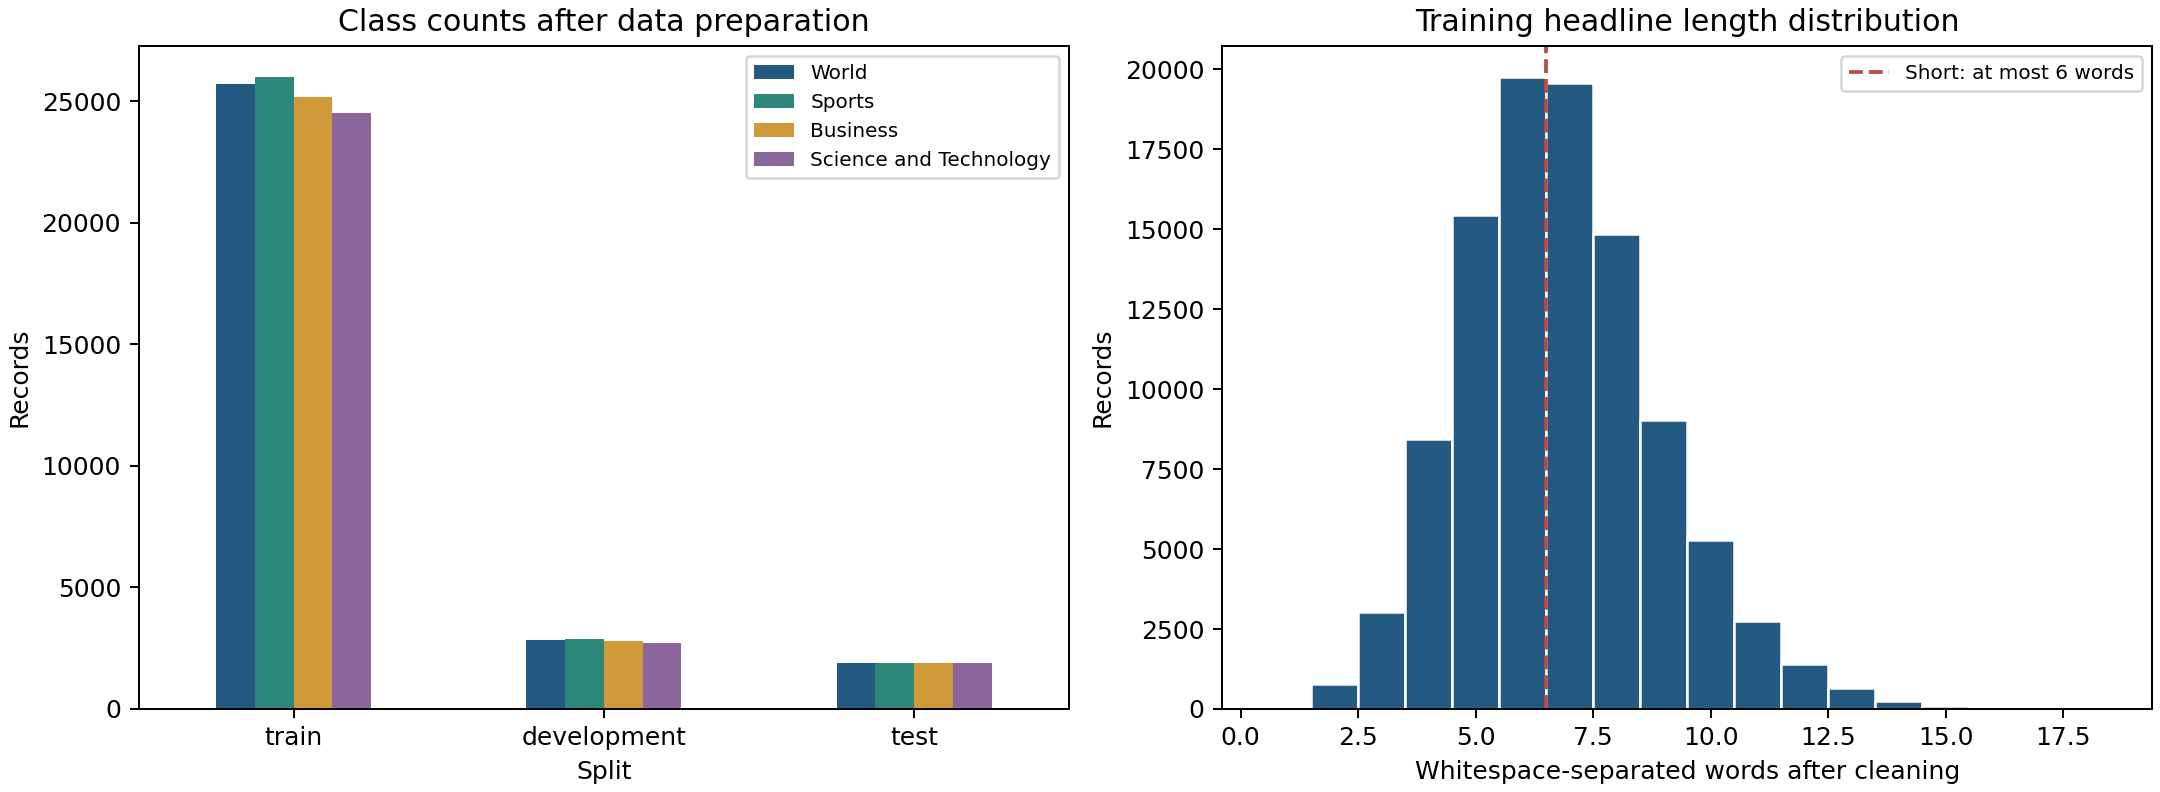

In [ ]:
# Plot class distribution and training title length
plt.rcParams.update({"font.size": 10, "figure.dpi": 120})
colors = ["#245a81", "#2d887b", "#d09a38", "#8a669d"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
class_counts.plot.bar(ax=axes[0], color=colors, rot=0)
axes[0].set_title("Class counts after data preparation")
axes[0].set_xlabel("Split")
axes[0].set_ylabel("Records")
axes[0].legend(fontsize=8)
max_words = int(train.word_count.max())
axes[1].hist(train.word_count, bins=np.arange(.5, max_words + 1.5), color=colors[0], edgecolor="white")
axes[1].axvline(6.5, color="#ba4b43", linestyle="--", label="Short: at most 6 words")
axes[1].set_title("Training headline length distribution")
axes[1].set_xlabel("Whitespace-separated words after cleaning")
axes[1].set_ylabel("Records")
axes[1].legend(fontsize=8)
fig.savefig(ROOT / "results/figures/data_overview.png", dpi=180)
plt.show()

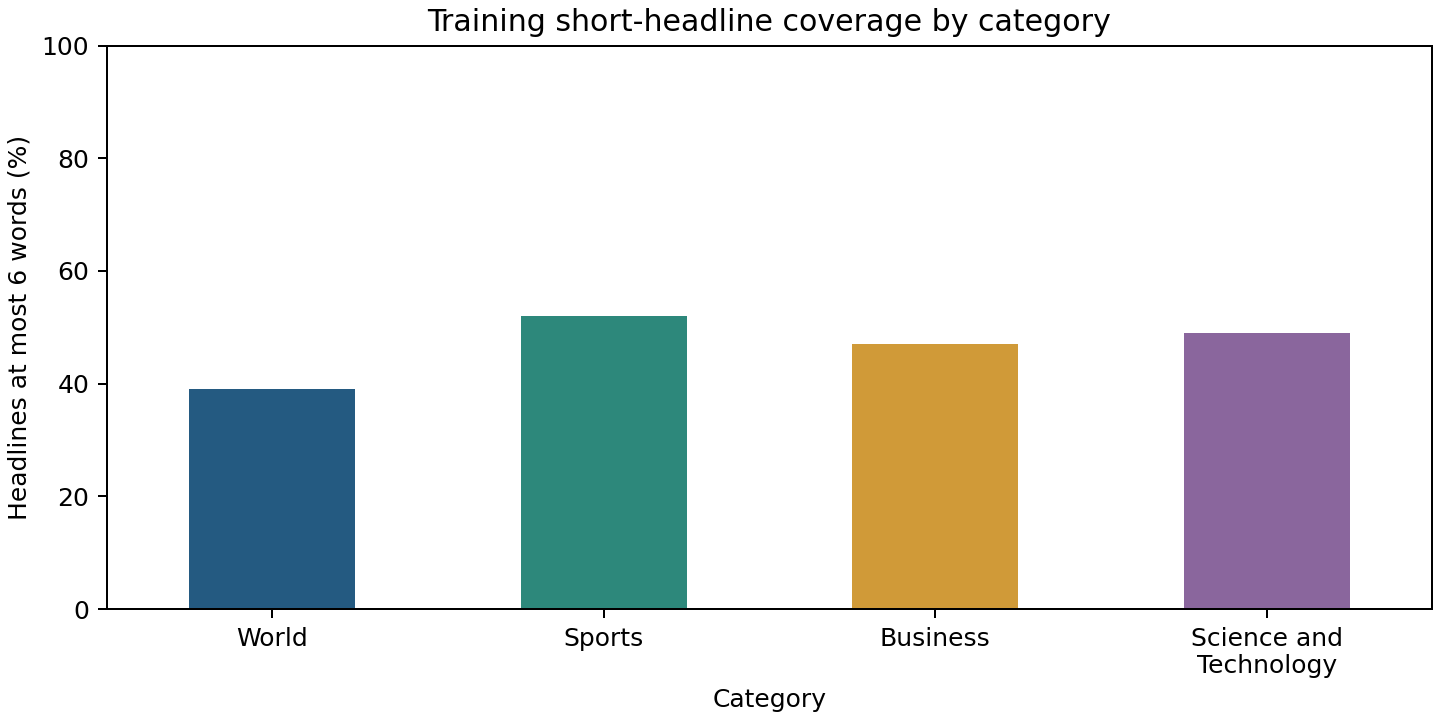

In [ ]:
# Plot short-headline coverage by category
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
(100 * short_counts.loc["train"] / class_counts.loc["train"]).plot.bar(ax=ax, color=colors, rot=0)
ax.set_xticklabels(["World", "Sports", "Business", "Science and\nTechnology"])
ax.set_title("Training short-headline coverage by category")
ax.set_xlabel("Category")
ax.set_ylabel("Headlines at most 6 words (%)")
ax.set_ylim(0, 100)
fig.savefig(ROOT / "results/figures/short_training_coverage.png", dpi=180)
plt.show()

In [ ]:
# Check saved splits against in-memory records
display(pd.DataFrame({
    "records": summary["split_counts"],
    "short_records": summary["short_counts"],
}))
assert leakage_checks.overlap.eq(0).all()
assert sum(summary["split_counts"].values()) + len(excluded) + len(empty_removed) == len(raw)
for name in splits:
    saved = pd.read_csv(ROOT / f"data/processed/{name}.csv", keep_default_na=False)
    assert saved.record_id.tolist() == splits[name].record_id.tolist()
    assert saved.text.tolist() == splits[name].text.tolist()
print("Phase 1 preparation and saved-output checks passed.")
print("Phase 1 is complete. Continue to Method 1 below; final test evaluation is pending.")

,records,short_records
train,101377,47462
development,11264,5255
test,7600,3643


## 04 · TF-IDF baseline

TF-IDF turns individual words and adjacent word pairs into numeric features for Logistic
Regression. The vocabulary and weights come from the training set. Try `C = 0.1, 1, 10` and
select by macro F1 on short development headlines. Break ties by full-development macro F1,
then by the smaller value of C. MiniLM uses the same selection rule.

In [ ]:
# @title Import model tools and define accuracy and macro F1
import gzip
import pickle
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd


from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from threadpoolctl import threadpool_limits


def score_predictions(y, predicted):
    return {"accuracy": float(accuracy_score(y, predicted)),
            "macro_f1": float(f1_score(y, predicted, labels=list(LABELS), average="macro", zero_division=0))}

In [ ]:
# @title Define TF-IDF training, development selection and checkpoint export
def train_baseline(train_frame, development_frame, root):
    """Do not pass the test set: model selection is restricted to development."""
    out = Path(root) / "results/baseline"
    out.mkdir(parents=True, exist_ok=True)
    config = {
        "C_grid": [0.1, 1.0, 10.0],
        "selection": "Highest short-development macro F1, then full-development macro F1, then smaller C.",
        "tfidf": {"lowercase": True, "ngram_range": [1, 2], "min_df": 2,
                  "max_df": 1.0, "max_features": 100000, "sublinear_tf": True,
                  "norm": "l2", "token_pattern": r"(?u)\b\w\w+\b"},
        "logistic_regression": {"solver": "lbfgs", "l1_ratio": 0.0, "max_iter": 1000,
                                "tol": 0.0001, "class_weight": None, "random_state": SEED},
        "seed": SEED,
        "final_test_evaluated": False,
    }
    # Persist the search protocol before observing candidate development scores.
    write_json(out / "selection_protocol.json", config)
    vectorizer = TfidfVectorizer(**{**config["tfidf"], "ngram_range": (1, 2)})
    started = time.perf_counter()
    x_train = vectorizer.fit_transform(train_frame.text)
    x_dev = vectorizer.transform(development_frame.text)
    short = development_frame.is_short.to_numpy(dtype=bool)
    assert short.any()
    trials = []
    best_key, best_classifier = None, None
    for c in config["C_grid"]:
        classifier = LogisticRegression(C=c, **config["logistic_regression"])
        t = time.perf_counter()
        with threadpool_limits(limits=2), warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            classifier.fit(x_train, train_frame.label)
        if any(issubclass(w.category, ConvergenceWarning) for w in caught):
            raise RuntimeError(f"C={c} did not converge; fix convergence before selecting a model.")
        predicted = classifier.predict(x_dev)
        full = score_predictions(development_frame.label, predicted)
        short_scores = score_predictions(development_frame.label.to_numpy()[short], predicted[short])
        row = {"C": c, "development_accuracy": full["accuracy"], "development_macro_f1": full["macro_f1"],
               "short_development_accuracy": short_scores["accuracy"],
               "short_development_macro_f1": short_scores["macro_f1"],
               "iterations": int(classifier.n_iter_.max()), "fit_seconds": time.perf_counter()-t}
        trials.append(row)
        print(f"C={c:g}: development macro F1={full['macro_f1']:.4f}; short macro F1={short_scores['macro_f1']:.4f}", flush=True)
        key = (short_scores["macro_f1"], full["macro_f1"], -c)
        if best_key is None or key > best_key:
            best_key, best_classifier = key, classifier
    pipeline = Pipeline([("tfidf", vectorizer), ("classifier", best_classifier)])
    predictions = pipeline.predict(development_frame.text)
    metrics = {"split": "development", "selected_C": best_classifier.C,
               "full": {"n": len(development_frame), **score_predictions(development_frame.label, predictions)},
               "short": {"n": int(short.sum()), **score_predictions(development_frame.label.to_numpy()[short], predictions[short])},
               "vocabulary_size": len(vectorizer.vocabulary_), "total_seconds": time.perf_counter()-started,
               "final_test_evaluated": False}
    pd.DataFrame(trials).to_csv(out / "development_search.csv", index=False)
    write_json(out / "development_metrics.json", metrics)
    records = development_frame[["record_id", "label", "text", "word_count", "is_short"]].copy()
    records["prediction"] = predictions
    records["correct"] = records.label.eq(records.prediction)
    records.to_csv(out / "development_predictions.csv", index=False)
    records.loc[~records.correct].to_csv(out / "development_errors.csv", index=False)
    report = classification_report(development_frame.label, predictions, labels=list(LABELS),
                                   target_names=list(LABELS.values()), output_dict=True, zero_division=0)
    write_json(out / "development_classification_report.json", report)
    matrix = confusion_matrix(development_frame.label, predictions, labels=list(LABELS))
    pd.DataFrame(matrix, index=LABELS.values(), columns=LABELS.values()).to_csv(out / "development_confusion_matrix.csv")
    models = Path(root) / "models"
    models.mkdir(exist_ok=True)
    with gzip.open(models / "tfidf_logistic_regression.pkl.gz", "wb") as stream:
        pickle.dump(pipeline, stream, protocol=pickle.HIGHEST_PROTOCOL)
    # Reload only our own locally produced artifact and verify identical inference.
    with gzip.open(models / "tfidf_logistic_regression.pkl.gz", "rb") as stream:
        restored = pickle.load(stream)
    assert np.array_equal(restored.predict(development_frame.text), predictions)
    return pipeline, pd.DataFrame(trials), metrics, matrix

In [ ]:
# @title Define single-headline TF-IDF prediction
def predict_news_topic(text, model):
    cleaned_text = clean_text(text)
    if not cleaned_text:
        return "Please enter a news headline or short news text."
    return LABELS[int(model.predict([cleaned_text])[0])]

In [ ]:
# Train TF-IDF and show development scores
# These are the exact Phase 1 records, with no repartitioning.
train_baseline_data = splits["train"]
development_baseline_data = splits["development"]
baseline_model, baseline_trials, baseline_metrics, baseline_confusion = train_baseline(
    train_baseline_data, development_baseline_data, ROOT,
)
display(baseline_trials)
display(pd.DataFrame({"Full development": baseline_metrics["full"],
                      "Short development": baseline_metrics["short"]}).T)
print("Selected C:", baseline_metrics["selected_C"])
print("Training-only vocabulary size:", baseline_metrics["vocabulary_size"])
print("Final test evaluated:", baseline_metrics["final_test_evaluated"])

,C,development_accuracy,development_macro_f1,short_development_accuracy,short_development_macro_f1,iterations,fit_seconds
0,0.1,0.828746,0.827398,0.808563,0.805399,57,4.162105
1,1.0,0.864790,0.863813,0.841675,0.838868,152,14.190436
2,10.0,0.868430,0.867552,0.845671,0.842988,201,42.540114


,n,accuracy,macro_f1
Full development,11264.0,0.868430,0.867552
Short development,5255.0,0.845671,0.842988


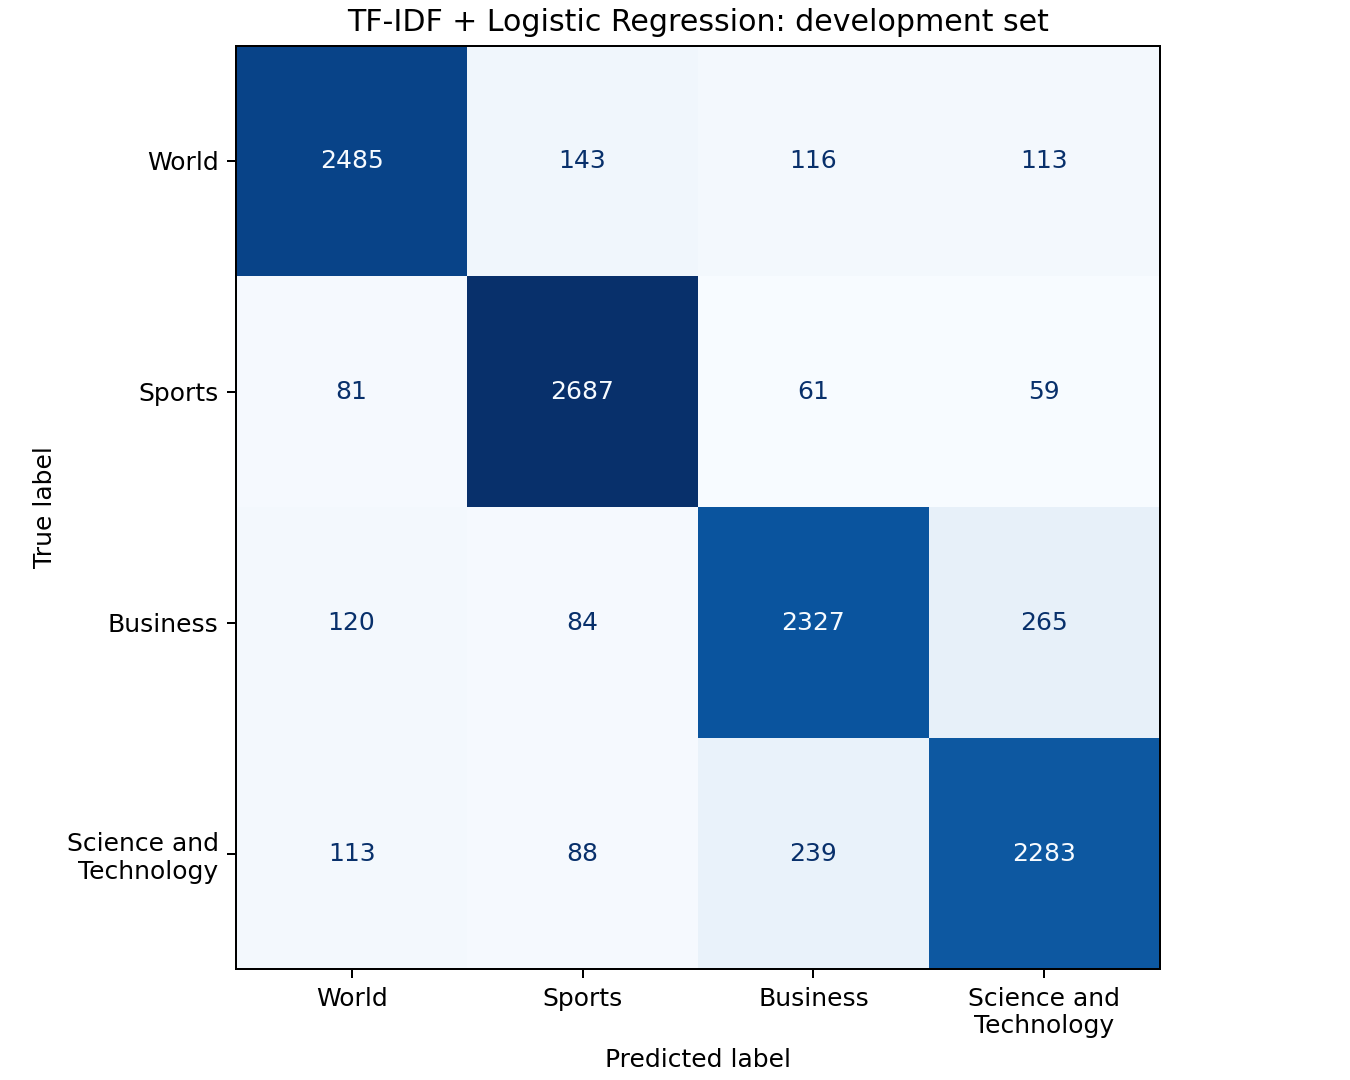

In [ ]:
# Plot the TF-IDF development confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(7.5, 6), constrained_layout=True)
ConfusionMatrixDisplay(baseline_confusion, display_labels=["World", "Sports", "Business", "Science and\nTechnology"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d",
)
ax.set_title("TF-IDF + Logistic Regression: development set")
fig.savefig(ROOT / "results/figures/baseline_development_confusion.png", dpi=180)
plt.show()

In [ ]:
# Try a headline with TF-IDF and check empty inputs
NEW_TEXT = "The team won the football final"
print(predict_news_topic(NEW_TEXT, baseline_model))

assert predict_news_topic("  ", baseline_model) == "Please enter a news headline or short news text."
assert predict_news_topic(None, baseline_model) == "Please enter a news headline or short news text."
assert predict_news_topic("zzzxxyy qqqrrr", baseline_model) in LABELS.values()
print("Empty-input and new-input checks passed.")

In [ ]:
# Verify the TF-IDF checkpoint
assert baseline_metrics["final_test_evaluated"] is False
assert baseline_model.named_steps["tfidf"].ngram_range == (1, 2)
print("Phase 2 baseline training, selection, save/reload and input checks passed.")
print("Next: frozen MiniLM embeddings with Logistic Regression using these same train/development records.")

## 05 · MiniLM embeddings

Frozen MiniLM encodes each headline as a 384-dimensional vector. Fit Logistic Regression on
these vectors using the same training and development records and the same C selection rule.
Before reusing an embedding cache, verify the input text, row order, model revision,
environment, and file checksum.

In [ ]:
# @title Import MiniLM and pin the encoder revision
from pathlib import Path
import gzip
import hashlib
import importlib.metadata
import json
import pickle
import time
import warnings

import numpy as np
import pandas as pd
import torch
from sentence_transformers import SentenceTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from threadpoolctl import threadpool_limits


MODEL_ID = "sentence-transformers/all-MiniLM-L6-v2"
MODEL_REVISION = "1110a243fdf4706b3f48f1d95db1a4f5529b4d41"

In [ ]:
# @title Define the frozen encoder
def load_encoder(root):
    torch.manual_seed(SEED)
    torch.set_num_threads(2)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    encoder = SentenceTransformer(
        MODEL_ID, revision=MODEL_REVISION, device=device,
        cache_folder=str(Path(root) / "data/model_cache"),
        trust_remote_code=False, token=False, model_kwargs={"use_safetensors": True},
    )
    encoder.eval()
    for parameter in encoder.parameters():
        parameter.requires_grad_(False)
    assert encoder.get_sentence_embedding_dimension() == 384
    assert encoder.max_seq_length == 256
    return encoder

In [ ]:
# @title Define batch encoding and verify the embedding cache
def embedding_cache_key(frame):
    h = hashlib.sha256()
    for record_id, text in zip(frame.record_id, frame.text):
        h.update(json.dumps([record_id, text], ensure_ascii=False).encode("utf-8") + b"\n")
    return h.hexdigest()


def generate_embeddings(frame, name, encoder, root):
    """Cache only representations matching text, order, model and environment."""
    cache = Path(root) / "data/embedding_cache"
    cache.mkdir(parents=True, exist_ok=True)
    path, meta_path = cache / f"{name}.npy", cache / f"{name}.json"
    metadata = {
        "record_text_order_sha256": embedding_cache_key(frame),
        "model_id": MODEL_ID, "revision": MODEL_REVISION,
        "normalize_embeddings": True, "max_seq_length": 256,
        "sentence_transformers": importlib.metadata.version("sentence-transformers"),
        "transformers": importlib.metadata.version("transformers"),
        "torch": torch.__version__, "device": str(encoder.device),
        "shape": [len(frame), 384], "dtype": "float32",
    }
    if path.exists() and meta_path.exists():
        existing = json.loads(meta_path.read_text())
        if all(existing.get(k) == v for k, v in metadata.items()) and existing.get("array_sha256") == sha256_file(path):
            array = np.load(path, allow_pickle=False)
            print(f"Verified {name} embedding cache: {array.shape}", flush=True)
            return array
    started = time.perf_counter()
    array = encoder.encode(frame.text.tolist(), batch_size=128, show_progress_bar=True,
                           convert_to_numpy=True, normalize_embeddings=True).astype(np.float32)
    assert array.shape == (len(frame), 384)
    assert np.isfinite(array).all()
    assert np.allclose(np.linalg.norm(array, axis=1), 1.0, atol=1e-5)
    np.save(path, array, allow_pickle=False)
    write_json(meta_path, {**metadata, "array_sha256": sha256_file(path),
                          "encoding_seconds": time.perf_counter()-started})
    print(f"Encoded {name}: {array.shape}", flush=True)
    return array

In [ ]:
# @title Define embedding classifier training and checkpoint export
def train_embedding_method(train_frame, development_frame, encoder, root):
    out = Path(root) / "results/embeddings"
    out.mkdir(parents=True, exist_ok=True)
    protocol = {
        "model_id": MODEL_ID, "revision": MODEL_REVISION,
        "frozen_encoder": True, "dimensions": 384, "normalize_embeddings": True,
        "C_grid": [0.1, 1.0, 10.0],
        "selection": "Highest short-development macro F1, then full-development macro F1, then smaller C.",
        "solver": "lbfgs", "l1_ratio": 0.0, "max_iter": 1000, "tol": 0.0001,
        "class_weight": None, "random_state": SEED, "final_test_evaluated": False,
    }
    write_json(out / "selection_protocol.json", protocol)
    x_train = generate_embeddings(train_frame, "train", encoder, root)
    x_dev = generate_embeddings(development_frame, "development", encoder, root)
    short = development_frame.is_short.to_numpy(dtype=bool)
    best_key, best_classifier, trials = None, None, []
    for c in protocol["C_grid"]:
        classifier = LogisticRegression(C=c, solver="lbfgs", l1_ratio=0.0, max_iter=1000,
                                        tol=0.0001, class_weight=None, random_state=SEED)
        started = time.perf_counter()
        with threadpool_limits(limits=2), warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            classifier.fit(x_train, train_frame.label)
        if any(issubclass(w.category, ConvergenceWarning) for w in caught):
            raise RuntimeError(f"Embedding classifier C={c} did not converge.")
        predicted = classifier.predict(x_dev)
        full = score_predictions(development_frame.label, predicted)
        subset = score_predictions(development_frame.label.to_numpy()[short], predicted[short])
        trials.append({"C": c, "development_accuracy": full["accuracy"],
                       "development_macro_f1": full["macro_f1"],
                       "short_development_accuracy": subset["accuracy"],
                       "short_development_macro_f1": subset["macro_f1"],
                       "iterations": int(classifier.n_iter_.max()),
                       "fit_seconds": time.perf_counter()-started})
        print(f"MiniLM C={c:g}: development macro F1={full['macro_f1']:.4f}; short macro F1={subset['macro_f1']:.4f}", flush=True)
        key = (subset["macro_f1"], full["macro_f1"], -c)
        if best_key is None or key > best_key:
            best_key, best_classifier = key, classifier
    predicted = best_classifier.predict(x_dev)
    metrics = {
        "split": "development", "model_id": MODEL_ID, "revision": MODEL_REVISION,
        "selected_C": best_classifier.C,
        "full": {"n": len(development_frame), **score_predictions(development_frame.label, predicted)},
        "short": {"n": int(short.sum()), **score_predictions(development_frame.label.to_numpy()[short], predicted[short])},
        "final_test_evaluated": False,
    }
    pd.DataFrame(trials).to_csv(out / "development_search.csv", index=False)
    write_json(out / "development_metrics.json", metrics)
    predictions = development_frame[["record_id", "label", "text", "word_count", "is_short"]].copy()
    predictions["prediction"] = predicted
    predictions["correct"] = predictions.label.eq(predictions.prediction)
    predictions.to_csv(out / "development_predictions.csv", index=False)
    predictions.loc[~predictions.correct].to_csv(out / "development_errors.csv", index=False)
    write_json(out / "development_classification_report.json", classification_report(
        development_frame.label, predicted, labels=list(LABELS), target_names=list(LABELS.values()),
        output_dict=True, zero_division=0))
    matrix = confusion_matrix(development_frame.label, predicted, labels=list(LABELS))
    pd.DataFrame(matrix, index=LABELS.values(), columns=LABELS.values()).to_csv(out / "development_confusion_matrix.csv")
    models = Path(root) / "models"
    models.mkdir(exist_ok=True)
    with gzip.open(models / "minilm_logistic_regression.pkl.gz", "wb") as stream:
        pickle.dump(best_classifier, stream, protocol=pickle.HIGHEST_PROTOCOL)
    with gzip.open(models / "minilm_logistic_regression.pkl.gz", "rb") as stream:
        restored = pickle.load(stream)
    assert np.array_equal(restored.predict(x_dev), predicted)
    token_lengths = [len(tokens) for tokens in encoder.tokenizer(
        train_frame.text.tolist(), truncation=False, add_special_tokens=True)["input_ids"]]
    write_json(out / "encoder_manifest.json", {
        "model_id": MODEL_ID, "revision": MODEL_REVISION, "dimensions": 384,
        "max_seq_length": encoder.max_seq_length, "device": str(encoder.device),
        "train_max_wordpiece_tokens_including_special": max(token_lengths),
        "train_headlines_exceeding_encoder_limit": sum(n > 256 for n in token_lengths),
        "parameters_frozen": all(not p.requires_grad for p in encoder.parameters()),
        "packages": {p: importlib.metadata.version(p) for p in
                     ["torch", "sentence-transformers", "transformers", "huggingface-hub", "tokenizers", "safetensors"]},
    })
    return best_classifier, pd.DataFrame(trials), metrics, matrix

In [ ]:
# @title Define single-headline MiniLM prediction
def predict_embedding_topic(text, encoder, classifier):
    value = clean_text(text)
    if not value:
        return "Please enter a news headline or short news text."
    vector = encoder.encode([value], normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)
    return LABELS[int(classifier.predict(vector)[0])]

In [ ]:
# Load and verify the frozen MiniLM encoder
embedding_encoder = load_encoder(ROOT)
print("Model:", MODEL_ID)
print("Pinned revision:", MODEL_REVISION)
print("Device:", embedding_encoder.device)
print("Embedding dimensions:", embedding_encoder.get_sentence_embedding_dimension())
assert all(not p.requires_grad for p in embedding_encoder.parameters())

In [ ]:
# Train the MiniLM classifier and show development scores
embedding_classifier, embedding_trials, embedding_metrics, embedding_confusion = train_embedding_method(
    splits["train"], splits["development"], embedding_encoder, ROOT,
)
display(embedding_trials)
display(pd.DataFrame({"Full development": embedding_metrics["full"],
                      "Short development": embedding_metrics["short"]}).T)
print("Selected C:", embedding_metrics["selected_C"])

,C,development_accuracy,development_macro_f1,short_development_accuracy,short_development_macro_f1,iterations,fit_seconds
0,0.1,0.830078,0.829211,0.804757,0.801534,49,10.579416
1,1.0,0.832919,0.832094,0.804948,0.801844,75,11.744808
2,10.0,0.833984,0.833111,0.806280,0.802972,154,56.188579


,n,accuracy,macro_f1
Full development,11264.0,0.833984,0.833111
Short development,5255.0,0.806280,0.802972


### Compare development results

Compare the methods on the full development set and its short-headline subset.
These scores are used to select the model settings.

In [ ]:
# Tabulate both methods on the development set
comparison_rows = []
for method, metrics in [("TF-IDF + Logistic Regression", baseline_metrics),
                        ("MiniLM + Logistic Regression", embedding_metrics)]:
    for subset in ["full", "short"]:
        comparison_rows.append({"method": method, "split": "development", "subset": subset,
                                **metrics[subset]})
development_comparison = pd.DataFrame(comparison_rows)
development_comparison.to_csv(ROOT / "results/development_method_comparison.csv", index=False)
display(development_comparison)

,method,split,subset,n,accuracy,macro_f1
0,TF-IDF + Logistic Regression,development,full,11264,0.868430,0.867552
1,TF-IDF + Logistic Regression,development,short,5255,0.845671,0.842988
2,MiniLM + Logistic Regression,development,full,11264,0.833984,0.833111
3,MiniLM + Logistic Regression,development,short,5255,0.806280,0.802972


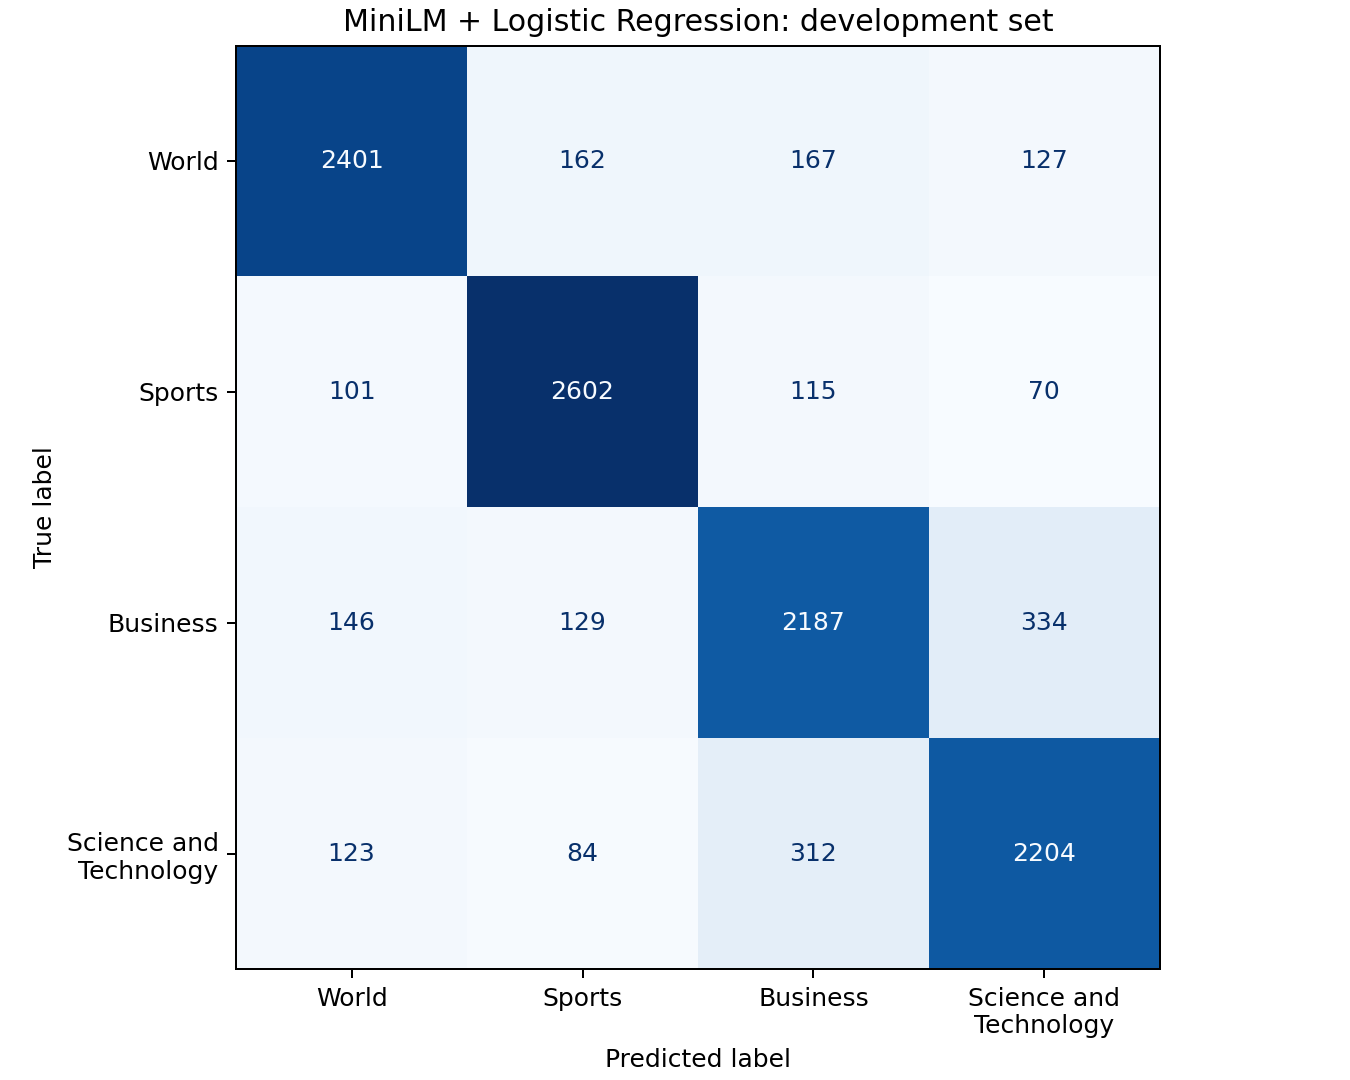

In [ ]:
# Plot the MiniLM development confusion matrix
fig, ax = plt.subplots(figsize=(7.5, 6), constrained_layout=True)
ConfusionMatrixDisplay(embedding_confusion, display_labels=["World", "Sports", "Business", "Science and\nTechnology"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("MiniLM + Logistic Regression: development set")
fig.savefig(ROOT / "results/figures/embedding_development_confusion.png", dpi=180)
plt.show()

In [ ]:
# @title Route new input to either trained method
def predict_selected_topic(text, method="minilm"):
    if method == "tfidf":
        return predict_news_topic(text, baseline_model)
    if method == "minilm":
        return predict_embedding_topic(text, embedding_encoder, embedding_classifier)
    raise ValueError("Choose tfidf or minilm.")

In [ ]:
# Try either model and check empty or unfamiliar inputs
NEW_TEXT = "The team won the football final"
SELECTED_METHOD = "minilm"
print(predict_selected_topic(NEW_TEXT, SELECTED_METHOD))
for method in ["tfidf", "minilm"]:
    assert predict_selected_topic("  ", method) == "Please enter a news headline or short news text."
    assert predict_selected_topic(None, method) == "Please enter a news headline or short news text."
    assert predict_selected_topic("zzzxxyy qqqrrr", method) in LABELS.values()
print("Both methods passed new-input and empty-input checks.")

In [ ]:
# Verify model selection and frozen encoder
assert not baseline_metrics["final_test_evaluated"]
assert not embedding_metrics["final_test_evaluated"]
assert all(not p.requires_grad for p in embedding_encoder.parameters())
# Final-test cache may exist when reproducing the completed experiment below.
print("Phase 3 embeddings, classifier selection, save/reload and input checks passed.")
print("Next: sealed final-test comparison and error analysis for both methods.")

## 06 · Final evaluation

Freeze the selected settings and score both models on the **same 7,600 official test records**
and the short-headline subset. Accuracy is the share of correct predictions. Macro F1 gives equal
weight to the F1 score of each category. The confusion matrices show which categories each
model confuses.

In [ ]:
# @title Import final evaluation tools
from pathlib import Path
import json
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
# @title Define paired test scoring and freeze the protocol
def evaluate_final_test(test, baseline_model, encoder, embedding_classifier, root):
    root = Path(root)
    out = root / "results/final"
    out.mkdir(parents=True, exist_ok=True)
    # Record the protocol before computing test predictions or scores.
    protocols = {name: json.loads((root / f"results/{name}/selection_protocol.json").read_text())
                 for name in ["baseline", "embeddings"]}
    selected = {name: json.loads((root / f"results/{name}/development_metrics.json").read_text())["selected_C"]
                for name in ["baseline", "embeddings"]}
    assert baseline_model.named_steps["classifier"].C == selected["baseline"]
    assert embedding_classifier.C == selected["embeddings"]
    frozen = {
        "question": "On AG News headlines of at most six words, how do TF-IDF with Logistic Regression and frozen MiniLM embeddings with Logistic Regression compare in accuracy and macro F1?",
        "short_max_whitespace_words_after_cleaning": SHORT_MAX_WORDS,
        "model_id": MODEL_ID, "model_revision": MODEL_REVISION,
        "selection_protocols": protocols, "selected_C": selected,
        "split_sha256": {s: sha256_file(root / f"data/processed/{s}.csv")
                          for s in ["train", "development", "test"]},
        "test_policy": "No model or threshold tuning using test results; reruns reproduce the frozen protocol.",
    }
    frozen_path = out / "frozen_protocol.json"
    if frozen_path.exists():
        if json.loads(frozen_path.read_text()) != frozen:
            raise RuntimeError("The final-test protocol changed. Preserve the previous experiment and document a new protocol before proceeding.")
    else:
        write_json(frozen_path, frozen)
    checks = pd.read_csv(root / "results/leakage_checks.csv")
    assert checks.overlap.eq(0).all()
    assert len(test) == 7600 and test.record_id.is_unique
    assert test.source_pool.eq("test").all()
    assert test.is_short.equals(test.word_count.between(1, SHORT_MAX_WORDS))
    predicted = {
        "TF-IDF + Logistic Regression": baseline_model.predict(test.text),
        "MiniLM + Logistic Regression": embedding_classifier.predict(
            generate_embeddings(test, "test", encoder, root)),
    }
    records = test[["record_id", "label", "text", "word_count", "is_short", "group_id"]].copy()
    records["tfidf_prediction"] = predicted["TF-IDF + Logistic Regression"]
    records["minilm_prediction"] = predicted["MiniLM + Logistic Regression"]
    records["tfidf_correct"] = records.label.eq(records.tfidf_prediction)
    records["minilm_correct"] = records.label.eq(records.minilm_prediction)
    records.to_csv(out / "test_predictions.csv", index=False)
    rows, reports, matrices = [], {}, {}
    for method, predictions in predicted.items():
        reports[method], matrices[method] = {}, {}
        for subset, mask in [("full", np.ones(len(test), dtype=bool)),
                             ("short", test.is_short.to_numpy(dtype=bool))]:
            truth = test.label.to_numpy()[mask]
            guesses = predictions[mask]
            rows.append({"method": method, "split": "test", "subset": subset,
                         "n": int(mask.sum()), **score_predictions(truth, guesses)})
            reports[method][subset] = classification_report(
                truth, guesses, labels=list(LABELS), target_names=list(LABELS.values()),
                output_dict=True, zero_division=0)
            matrix = confusion_matrix(truth, guesses, labels=list(LABELS))
            matrices[method][subset] = matrix
            slug = "tfidf" if method.startswith("TF-IDF") else "minilm"
            pd.DataFrame(matrix, index=LABELS.values(), columns=LABELS.values()).to_csv(
                out / f"{slug}_{subset}_confusion_matrix.csv")
    table = pd.DataFrame(rows)
    table.to_csv(out / "test_metrics.csv", index=False)
    write_json(out / "test_metrics.json", rows)
    write_json(out / "classification_reports.json", reports)
    counts = pd.DataFrame({
        "full": test.label.value_counts().reindex(LABELS, fill_value=0),
        "short": test.loc[test.is_short].label.value_counts().reindex(LABELS, fill_value=0),
    }).rename(index=LABELS)
    counts.to_csv(out / "test_class_counts.csv")
    combinations = pd.crosstab(records.tfidf_correct, records.minilm_correct).reindex(
        index=[False, True], columns=[False, True], fill_value=0)
    combinations.to_csv(out / "paired_correctness.csv")
    return table, records, matrices, counts

In [ ]:
# @title Define the three checked error cases
def analyze_test_errors(records, baseline_model, root):
    """Explain three observed short-headline cases without changing either model."""
    cases = [
        {
            "record_id": "test:000013", "expected": (4, 2, 4),
            "pattern": "TF-IDF wrong; MiniLM correct",
            "explanation": "The title concerns an ant colony, but the lexical classifier selects Sports. In its Sports-versus-Science-and-Technology logit margin, 'australia', 'super' and 'hits' have positive contributions, while 'colony' opposes that margin. This is direct evidence of misleading learned lexical associations for this example. MiniLM returns the dataset's Science and Technology label; the prediction alone does not reveal its internal cause.",
        },
        {
            "record_id": "test:000103", "expected": (3, 3, 4),
            "pattern": "MiniLM wrong; TF-IDF correct",
            "explanation": "The headline mixes a biotechnology industry topic with a downturn framing. MiniLM returns Science and Technology although the dataset label is Business. A possible explanation is emphasis on the industry domain rather than the business framing; this is a hypothesis, not an attribution analysis of MiniLM. The lexical model's learned weights for 'biotech' and 'surviving' favor Business over Science and Technology. 'Downturns' is absent from this fitted vocabulary, so it is not credited with that model's correct decision.",
        },
        {
            "record_id": "test:000111", "expected": (4, 3, 3),
            "pattern": "Both methods wrong",
            "explanation": "The dataset label is Science and Technology, while both methods return Business. A technology company acquisition also reads as business news when only its title is available. In the lexical model, 'buys' and 'firms' support Business over Science and Technology, while 'ibm' opposes it. This illustrates topic overlap and limited context. The dataset label is retained; this example does not establish a labelling error.",
        },
    ]
    by_id = records.set_index("record_id")
    vectorizer = baseline_model.named_steps["tfidf"]
    classifier = baseline_model.named_steps["classifier"]
    terms = vectorizer.get_feature_names_out()
    explained = []
    for case in cases:
        row = by_id.loc[case["record_id"]]
        actual = (int(row.label), int(row.tfidf_prediction), int(row.minilm_prediction))
        if actual != case["expected"]:
            raise RuntimeError("An illustrated prediction changed; review its explanation before submission.")
        assert row.is_short and not (row.tfidf_correct and row.minilm_correct)
        vector = vectorizer.transform([row.text])
        predicted_class = int(row.tfidf_prediction)
        # Compare to Sci/Tech in these three cases, including the correct Business case.
        a = list(classifier.classes_).index(predicted_class)
        b = list(classifier.classes_).index(4)
        contributions = vector.data * (classifier.coef_[a, vector.indices] - classifier.coef_[b, vector.indices])
        evidence = sorted([{"term": str(term), "logit_margin_contribution": float(value)}
                           for term, value in zip(terms[vector.indices], contributions)],
                          key=lambda item: -item["logit_margin_contribution"])
        explained.append({
            "record_id": case["record_id"], "text": row.text, "word_count": int(row.word_count),
            "true_class": LABELS[int(row.label)],
            "tfidf_prediction": LABELS[int(row.tfidf_prediction)],
            "minilm_prediction": LABELS[int(row.minilm_prediction)],
            "pattern": case["pattern"], "explanation": case["explanation"],
            "tfidf_evidence": {"margin": f"{LABELS[predicted_class]} minus Science and Technology",
                               "term_contributions": evidence,
                               "note": "Additive feature contributions to a pairwise logit margin, not probabilities or an explanation of MiniLM."},
        })
    assert "downturns" not in vectorizer.vocabulary_
    write_json(Path(root) / "results/final/error_analysis.json", explained)
    pd.DataFrame([{k: v for k, v in case.items() if k != "tfidf_evidence"} for case in explained]).to_csv(
        Path(root) / "results/final/error_analysis.csv", index=False)
    return explained

In [ ]:
# @title Define the written results report
def summarize_findings(table, root):
    lookup = table.set_index(["method", "subset"])
    lexical = lookup.loc[("TF-IDF + Logistic Regression", "short")]
    semantic = lookup.loc[("MiniLM + Logistic Regression", "short")]
    text = f"""# Final News Topic Classification Findings

## Experimental question and answer

On AG News headlines of at most six whitespace-separated words after shared cleaning, TF-IDF with Logistic Regression outperformed frozen all-MiniLM-L6-v2 embeddings with Logistic Regression in this experiment. On the same {int(lexical['n']):,} short test headlines, accuracy was {lexical['accuracy']:.2%} versus {semantic['accuracy']:.2%}, and macro F1 was {lexical['macro_f1']:.2%} versus {semantic['macro_f1']:.2%}. The macro F1 difference was {100*(lexical['macro_f1']-semantic['macro_f1']):.2f} percentage points in favor of TF-IDF.

## Protocol

Both methods learned their classifiers from the same 101,377 training titles. C was selected on the same 11,264 development titles using short-development macro F1, overall development macro F1, then smaller C. Both selected C=10 from [0.1, 1, 10]. No training or setting selection used the 7,600 official test labels. The test was used only after protocols were frozen; reruns reproduce that comparison. Both methods used titles only and identical test records. The frozen protocol and split hashes are saved alongside the results.

## Test results

| Method | Subset | Records | Accuracy | Macro F1 |
|---|---|---:|---:|---:|
"""
    for row in table.to_dict("records"):
        text += f"| {row['method']} | {row['subset']} | {row['n']:,} | {row['accuracy']:.2%} | {row['macro_f1']:.2%} |\n"
    text += """
## Error analysis and interpretation

Three short-headline cases in error_analysis.json illustrate a lexical failure corrected by MiniLM, a MiniLM failure corrected by the lexical model, and a shared error. Linear feature contributions substantiate the stated TF-IDF associations. Proposed reasons for MiniLM errors are explicitly hypotheses; no internal attribution was performed. These are illustrative cases selected after scoring, not a random estimate of error causes.

The results show that generic semantic representations did not improve this title-only task under the tested frozen-encoder protocol. They do not establish a universal ranking of traditional and pretrained models. A plausible explanation is that corpus-specific lexical associations are useful here, while a generic frozen encoder may not preserve the distinctions required by the labels. The experiment does not isolate that mechanism.

## Limitations and future work

Titles omit the descriptions on which topic context may depend, and business/technology boundaries can be ambiguous. The declared grouping rules cannot identify every semantic paraphrase or related event. The preserved official test includes 40 repeated normalized-title rows beyond first occurrences, so row-level metrics are not based on completely independent observations. Potential overlap with the pretrained encoder's external training corpus cannot be ruled out. The study uses one split seed and a small predefined C grid; no significance test or interval estimate is claimed.

A future experiment could compare controlled encoder fine-tuning against the frozen encoder using a new, prespecified evaluation plan and a fresh held-out evaluation resource. The existing test results must not be used for iterative model tuning. This future work is not part of the implemented approved comparison.

## Remaining submission work

These findings are experiment evidence, not the final eight-page report. GitHub, native Colab/Jupyter fresh-session confirmation, the seven-section report, team appendix, original member examples and dated contributions, PowerPoint, rehearsal and final ZIP/rubric audit remain to be completed.
"""
    Path(root, "results/final/experiment_findings.md").write_text(text, encoding="utf-8")
    return text

In [ ]:
# Evaluate both models on the held-out test
final_metrics, final_predictions, final_matrices, final_class_counts = evaluate_final_test(
    splits["test"], baseline_model, embedding_encoder, embedding_classifier, ROOT,
)
display(final_metrics)
display(final_class_counts)
assert final_metrics.groupby("subset").n.nunique().eq(1).all()
print("Full test records:", len(final_predictions))
print("Short test records:", int(final_predictions.is_short.sum()))

,method,split,subset,n,accuracy,macro_f1
0,TF-IDF + Logistic Regression,test,full,7600,0.868684,0.868360
1,TF-IDF + Logistic Regression,test,short,3643,0.846006,0.844514
2,MiniLM + Logistic Regression,test,full,7600,0.834868,0.834614
3,MiniLM + Logistic Regression,test,short,3643,0.805380,0.804869


,full,short
label,,
World,1900,770
Sports,1900,1005
Business,1900,920
Science and Technology,1900,948


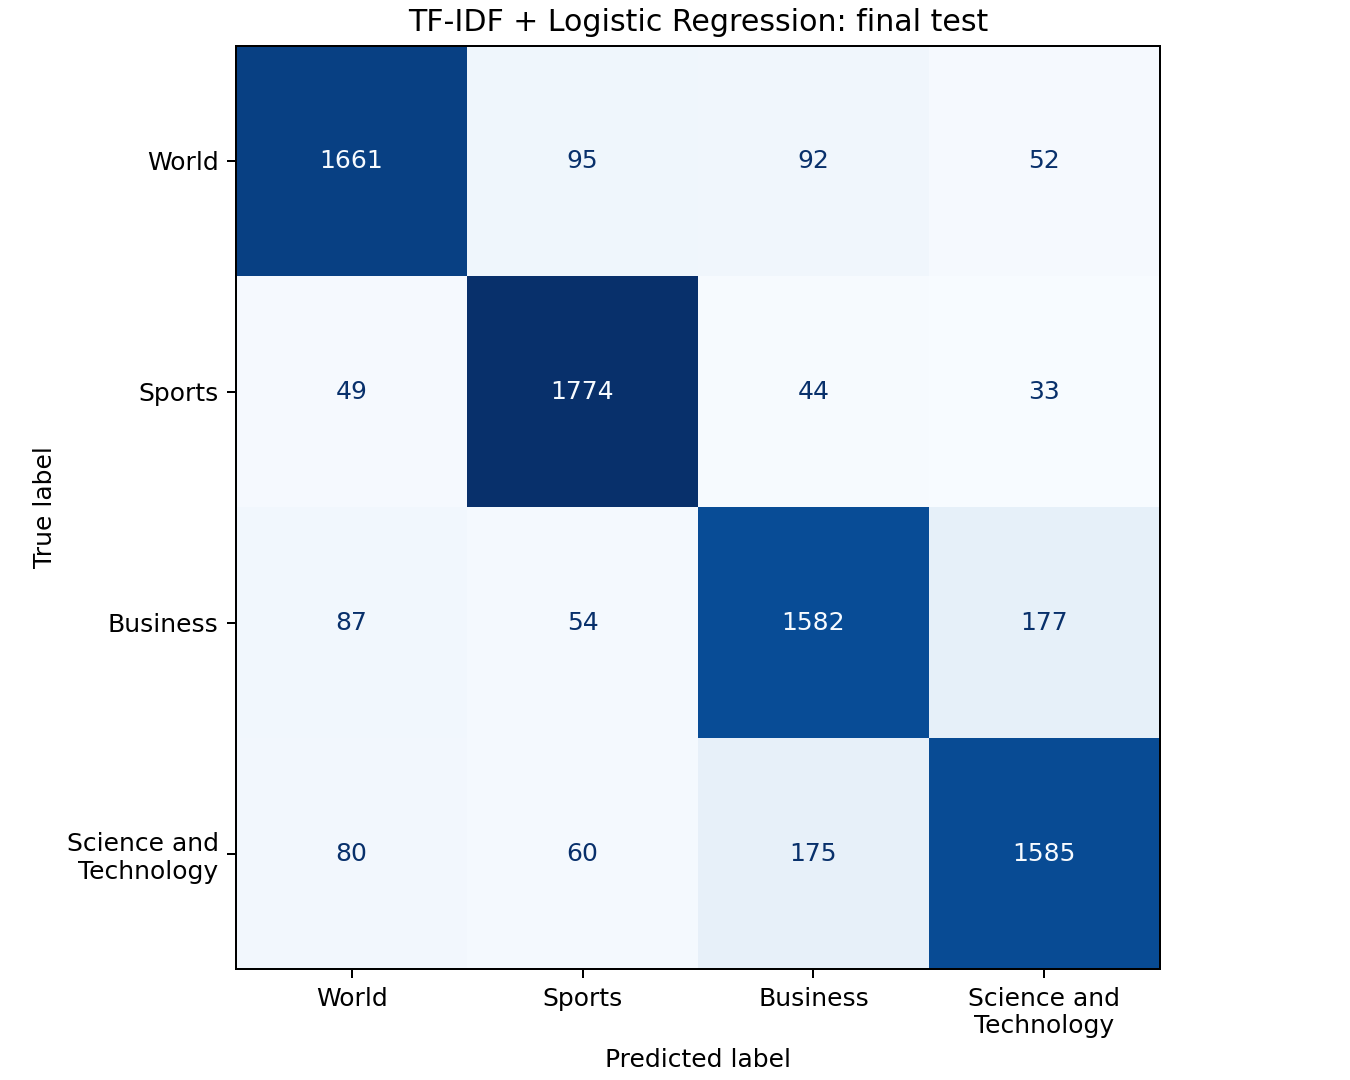

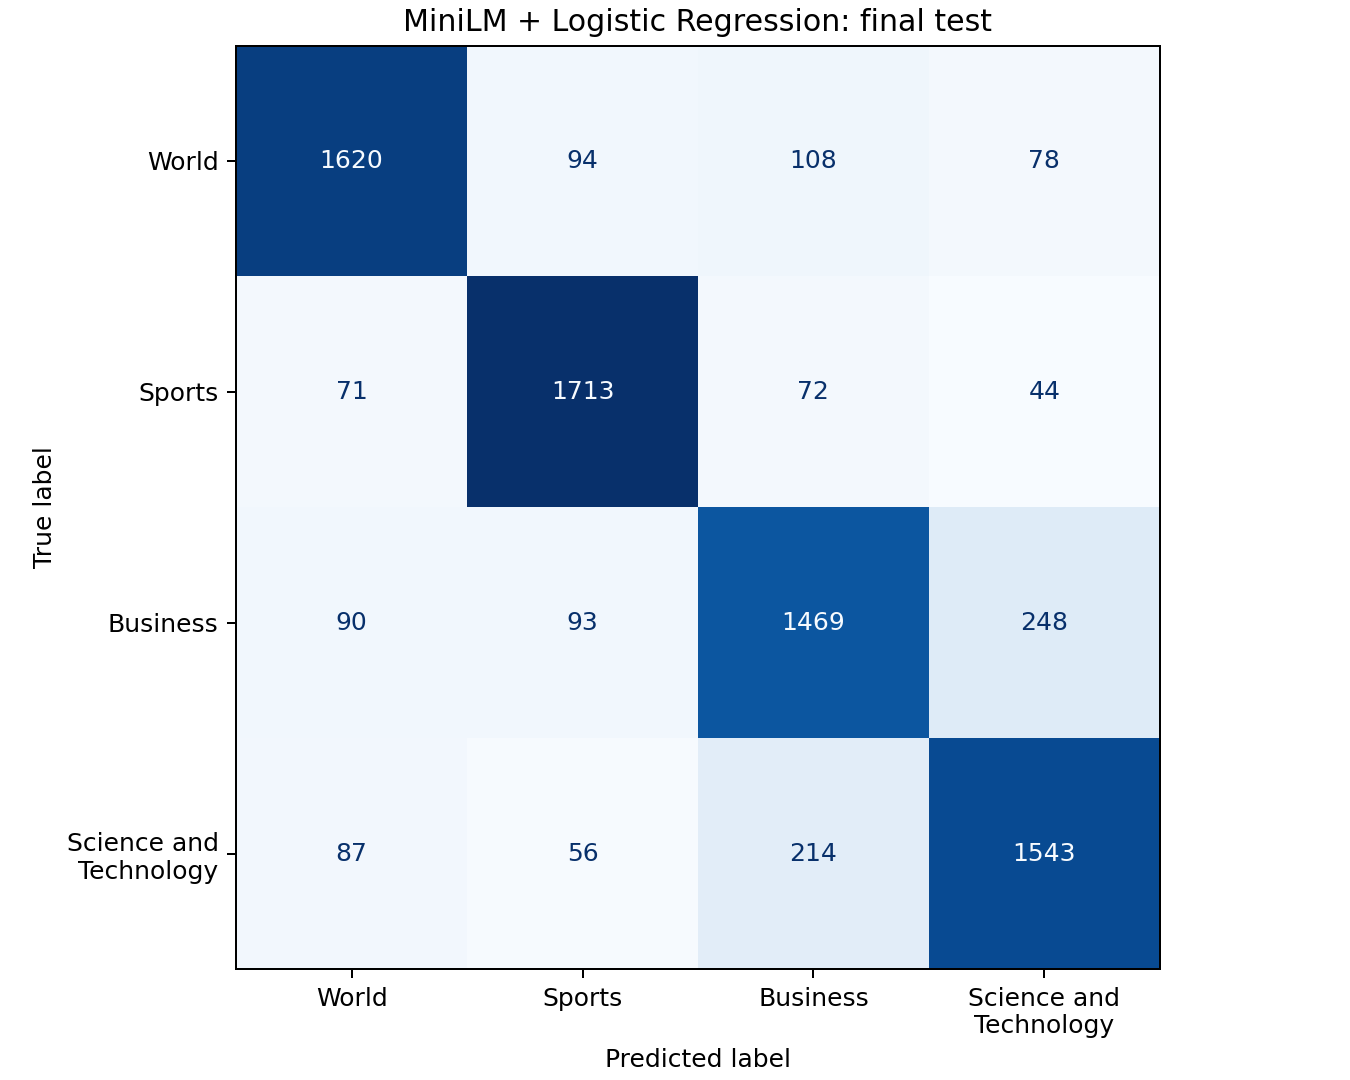

In [ ]:
# Plot the two final confusion matrices
for method, matrices in final_matrices.items():
    fig, ax = plt.subplots(figsize=(7.5, 6), constrained_layout=True)
    ConfusionMatrixDisplay(matrices["full"], display_labels=["World", "Sports", "Business", "Science and\nTechnology"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(method + ": final test")
    slug = "tfidf" if method.startswith("TF-IDF") else "minilm"
    fig.savefig(ROOT / f"results/figures/{slug}_final_test_confusion.png", dpi=180)
    plt.show()

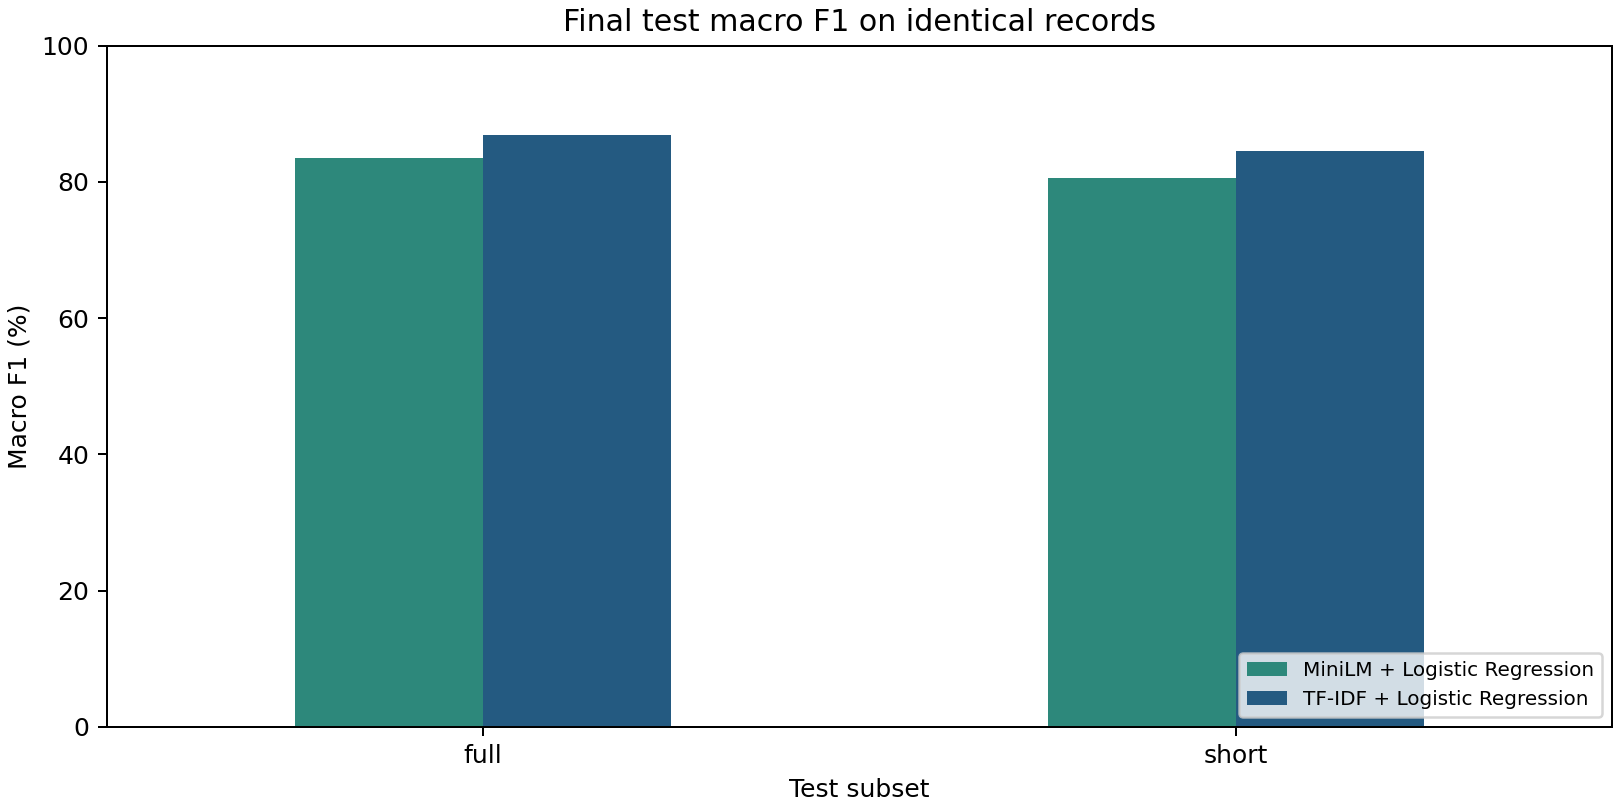

In [ ]:
# Plot macro F1 on the full and short test sets
comparison = final_metrics.pivot(index="subset", columns="method", values="macro_f1").reindex(["full", "short"])
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
(100 * comparison).plot.bar(ax=ax, color=["#2d887b", "#245a81"], rot=0)
ax.set_title("Final test macro F1 on identical records")
ax.set_xlabel("Test subset")
ax.set_ylabel("Macro F1 (%)")
ax.set_ylim(0, 100)
ax.legend(fontsize=8, loc="lower right")
fig.savefig(ROOT / "results/figures/final_macro_f1_comparison.png", dpi=180)
plt.show()

## 07 · Error analysis and findings

Review three short headlines. TF-IDF misses the first, MiniLM misses the second, and both
methods miss the third. Measured term contributions support the TF-IDF explanations.
The proposed reasons for MiniLM errors are hypotheses.

In [ ]:
# Inspect the three observed misclassifications
error_cases = analyze_test_errors(final_predictions, baseline_model, ROOT)
display(pd.DataFrame([{k: v for k, v in case.items() if k != "tfidf_evidence"} for case in error_cases]))
for case in error_cases:
    print(case["record_id"], "—", case["text"])
    print("True:", case["true_class"], "| TF-IDF:", case["tfidf_prediction"], "| MiniLM:", case["minilm_prediction"])
    print(case["explanation"], "\n")
assert len(error_cases) >= 3

test:000013 — Super ant colony hits Australia
True: Science and Technology | TF-IDF: Sports | MiniLM: Science and Technology
The title concerns an ant colony, but the lexical classifier selects Sports. In its Sports-versus-Science-and-Technology logit margin, 'australia', 'super' and 'hits' have positive contributions, while 'colony' opposes that margin. This is direct evidence of misleading learned lexical associations for this example. MiniLM returns the dataset's Science and Technology label; the prediction alone does not reveal its internal cause. 

test:000103 — Surviving Biotech's Downturns
True: Business | TF-IDF: Business | MiniLM: Science and Technology
The headline mixes a biotechnology industry topic with a downturn framing. MiniLM returns Science and Technology although the dataset label is Business. A possible explanation is emphasis on the industry domain rather than the business framing; this is a hypothesis, not an attribution analysis of MiniLM. The lexical model's lea

,record_id,text,word_count,true_class,tfidf_prediction,minilm_prediction,pattern,explanation
0,test:000013,Super ant colony hits Australia,5,Science and Technology,Sports,Science and Technology,TF-IDF wrong; MiniLM correct,"The title concerns an ant colony, but the lexi..."
1,test:000103,Surviving Biotech's Downturns,3,Business,Business,Science and Technology,MiniLM wrong; TF-IDF correct,The headline mixes a biotechnology industry to...
2,test:000111,IBM Buys Two Danish Services Firms,6,Science and Technology,Business,Business,Both methods wrong,"The dataset label is Science and Technology, w..."


### New headlines and experimental findings

The new headlines illustrate prediction and are excluded from test metrics. The report reads
accuracy and macro F1 from the evaluation results. Key limitations include the limited context
of headlines, imperfect related-story detection, and possible overlap between AG News and
MiniLM's pretraining data.

In [ ]:
# Classify new demonstration headlines
demonstration_texts = [
    "Parliament approves a new international peace agreement",
    "The national team wins the basketball final",
    "Retail company reports a rise in quarterly profits",
    "Researchers develop a faster quantum computing chip",
]
demonstrations = pd.DataFrame({"new_text": demonstration_texts})
for method in ["tfidf", "minilm"]:
    demonstrations[method] = [predict_selected_topic(text, method) for text in demonstration_texts]
demonstrations["source"] = "Demonstration input"
demonstrations.to_csv(ROOT / "results/final/new_input_demonstrations.csv", index=False)
display(demonstrations[["new_text", "tfidf", "minilm"]])
for method in ["tfidf", "minilm"]:
    assert predict_selected_topic("", method) == "Please enter a news headline or short news text."

,new_text,tfidf,minilm
0,Parliament approves a new international peace ...,World,World
1,The national team wins the basketball final,Sports,Sports
2,Retail company reports a rise in quarterly pro...,Business,Business
3,Researchers develop a faster quantum computing...,Science and Technology,Science and Technology


In [ ]:
# Display the findings and verify the result records
from IPython.display import Markdown
findings = summarize_findings(final_metrics, ROOT)
display(Markdown(findings))
assert final_metrics.split.eq("test").all()
assert set(final_predictions.record_id) == set(splits["test"].record_id)
print("Phase 4 paired test evaluation, figures, error analysis and new-input checks passed.")
print("Next: GitHub and final reproducibility verification, then report, appendix and presentation.")

# Final News Topic Classification Findings

## Experimental question and answer

On AG News headlines of at most six whitespace-separated words after shared cleaning, TF-IDF with Logistic Regression outperformed frozen all-MiniLM-L6-v2 embeddings with Logistic Regression in this experiment. On the same 3,643 short test headlines, accuracy was 84.60% versus 80.54%, and macro F1 was 84.45% versus 80.49%. The macro F1 difference was 3.96 percentage points in favor of TF-IDF.

## Protocol

Both methods learned their classifiers from the same 101,377 training titles. C was selected on the same 11,264 development titles using short-development macro F1, overall development macro F1, then smaller C. Both selected C=10 from [0.1, 1, 10]. No training or setting selection used the 7,600 official test labels. The test was used only after protocols were frozen; reruns reproduce that comparison. Both methods used titles only and identical test records. The frozen protocol and split hashes are saved alongside the results.

## Test results

| Method | Subset | Records | Accuracy | Macro F1 |
|---|---|---:|---:|---:|
| TF-IDF + Logistic Regression | full | 7,600 | 86.87% | 86.84% |
| TF-IDF + Logistic Regression | short | 3,643 | 84.60% | 84.45% |
| MiniLM + Logistic Regression | full | 7,600 | 83.49% | 83.46% |
| MiniLM + Logistic Regression | short | 3,643 | 80.54% | 80.49% |

## Error analysis and interpretation

Three short-headline cases in error_analysis.json illustrate a lexical failure corrected by MiniLM, a MiniLM failure corrected by the lexical model, and a shared error. Linear feature contributions substantiate the stated TF-IDF associations. Proposed reasons for MiniLM errors are explicitly hypotheses; no internal attribution was performed. These are illustrative cases selected after scoring, not a random estimate of error causes.

The results show that generic semantic representations did not improve this title-only task under the tested frozen-encoder protocol. They do not establish a universal ranking of traditional and pretrained models. A plausible explanation is that corpus-specific lexical associations are useful here, while a generic frozen encoder may not preserve the distinctions required by the labels. The experiment does not isolate that mechanism.

## Limitations and future work

Titles omit the descriptions on which topic context may depend, and business/technology boundaries can be ambiguous. The declared grouping rules cannot identify every semantic paraphrase or related event. The preserved official test includes 40 repeated normalized-title rows beyond first occurrences, so row-level metrics are not based on completely independent observations. Potential overlap with the pretrained encoder's external training corpus cannot be ruled out. The study uses one split seed and a small predefined C grid; no significance test or interval estimate is claimed.

A future experiment could compare controlled encoder fine-tuning against the frozen encoder using a new, prespecified evaluation plan and a fresh held-out evaluation resource. The existing test results must not be used for iterative model tuning. This future work is not part of the implemented approved comparison.

## Remaining submission work

These findings are experiment evidence, not the final eight-page report. GitHub, native Colab/Jupyter fresh-session confirmation, the seven-section report, team appendix, original member examples and dated contributions, PowerPoint, rehearsal and final ZIP/rubric audit remain to be completed.


## 08 · Live demo

Enter an English headline or choose an example. Select **TF-IDF**, **MiniLM**, or
**Compare both** to display a prediction, category scores, and word count from the fitted
models in this session. Use the plain-text cell below if the widgets do not appear.

In [ ]:
# @title Import live inference tools
from pathlib import Path
import base64
import gzip
import hashlib
import html
import pickle
import re
import numpy as np
import pandas as pd
from sklearn.utils.validation import check_is_fitted

In [ ]:
# @title Define live inference, scores and input warnings
class NewsClassifier:
    LABELS = {1: 'World', 2: 'Sports', 3: 'Business', 4: 'Science and Technology'}
    MODEL_ID = 'sentence-transformers/all-MiniLM-L6-v2'
    REVISION = '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'

    def __init__(self, tfidf_model, minilm_classifier, encoder=None, source='current training run'):
        check_is_fitted(tfidf_model)
        check_is_fitted(minilm_classifier)
        for model in [tfidf_model, minilm_classifier]:
            if list(model.classes_) != list(self.LABELS):
                raise ValueError('Both fitted classifiers must contain labels 1, 2, 3 and 4 in order.')
        if minilm_classifier.n_features_in_ != 384:
            raise ValueError('The MiniLM classifier requires 384-dimensional embeddings.')
        self.models = {'tfidf': tfidf_model, 'minilm': minilm_classifier}
        self.encoder = encoder
        self.source = source

    @classmethod
    def from_embedded(cls, artifacts):
        """Load only this project's supplied checkpoint; a checksum is not a trust signature."""
        models = {}
        for name, item in artifacts.items():
            payload = base64.b64decode(item['base64'], validate=True)
            if hashlib.sha256(payload).hexdigest() != item['sha256']:
                raise ValueError('Packaged model checksum mismatch: ' + name)
            models[name] = pickle.loads(gzip.decompress(payload))
        return cls(models['tfidf'], models['minilm'], source='packaged reference checkpoint')

    @staticmethod
    def clean(value):
        if value is None or pd.isna(value):
            return ''
        return ' '.join(html.unescape(str(value)).split())

    def _encoder(self):
        if self.encoder is None:
            import torch
            from sentence_transformers import SentenceTransformer
            torch.manual_seed(42)
            torch.set_num_threads(2)
            encoder = SentenceTransformer(
                self.MODEL_ID, revision=self.REVISION,
                device='cuda' if torch.cuda.is_available() else 'cpu',
                cache_folder=str(Path.cwd() / 'news_demo_encoder_cache'),
                trust_remote_code=False, token=False, model_kwargs={'use_safetensors': True})
            encoder.eval()
            for parameter in encoder.parameters():
                parameter.requires_grad_(False)
            if encoder.get_sentence_embedding_dimension() != 384 or encoder.max_seq_length != 256:
                raise ValueError('Unexpected encoder configuration.')
            self.encoder = encoder
        return self.encoder

    def predict_details(self, value, method='tfidf'):
        if method not in self.models:
            raise ValueError('Select tfidf or minilm.')
        text = self.clean(value)
        if not text:
            return {'prediction': None, 'message': 'Please enter an English news headline.',
                    'scores': {}, 'warnings': [], 'word_count': 0, 'is_short': False}
        warnings = []
        if not re.search('[A-Za-z]', text):
            warnings.append('No English letters detected. This model was evaluated on English news only.')
        if method == 'tfidf':
            features = self.models['tfidf'].named_steps['tfidf'].transform([text])
            if features.nnz == 0:
                warnings.append('No words matched the trained TF-IDF vocabulary. The forced label is based on class intercepts.')
            probabilities = self.models['tfidf'].named_steps['classifier'].predict_proba(features)[0]
        else:
            encoder = self._encoder()
            ids = encoder.tokenizer(text, truncation=False, add_special_tokens=True)['input_ids']
            if len(ids) > encoder.max_seq_length:
                warnings.append(f'Input has {len(ids)} wordpieces; MiniLM uses only the first {encoder.max_seq_length}.')
            features = encoder.encode([text], normalize_embeddings=True, convert_to_numpy=True,
                                      show_progress_bar=False)
            probabilities = self.models['minilm'].predict_proba(features)[0]
        if probabilities.shape != (4,) or not np.isfinite(probabilities).all():
            raise RuntimeError('The classifier returned invalid scores.')
        count = len(text.split())
        return {'prediction': self.LABELS[int(np.argmax(probabilities)) + 1],
                'scores': {self.LABELS[k]: float(probabilities[k - 1]) for k in self.LABELS},
                'warnings': warnings, 'word_count': count, 'is_short': 1 <= count <= 6,
                'method': method, 'source': self.source}

    def predict(self, value, method='tfidf'):
        details = self.predict_details(value, method)
        return details['prediction'] or details['message']

In [ ]:
# Connect the interface to the fitted models
required_names = ['baseline_model', 'embedding_classifier', 'embedding_encoder']
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError('Run the training cells above before launching this interface, or use News_Classifier_Ready.ipynb. Missing: ' + ', '.join(missing_names))
news_app = NewsClassifier(baseline_model, embedding_classifier, embedding_encoder)
assert news_app.models['tfidf'] is baseline_model
assert news_app.models['minilm'] is embedding_classifier
assert news_app.encoder is embedding_encoder
print('Interface source:', news_app.source)

In [ ]:
# @title Import interactive widgets
from html import escape
import ipywidgets as widgets
from IPython.display import display

In [ ]:
# @title Define the live controls and prediction display
def build_demo(app, show=True):
    try:
        from google.colab import output
    except ImportError:
        pass
    else:
        output.enable_custom_widget_manager()
    headline = widgets.Textarea(placeholder='Enter an English news headline...', rows=4,
                               layout=widgets.Layout(width='100%'))
    method = widgets.Dropdown(description='Model:', value='tfidf', options=[
        ('TF-IDF + Logistic Regression', 'tfidf'), ('MiniLM + Logistic Regression', 'minilm'),
        ('Compare both', 'both')], layout=widgets.Layout(width='100%'))
    example = widgets.Dropdown(description='Example:', options=[('Custom input', ''),
        ('World', 'Parliament approves an international peace agreement'),
        ('Sports', 'The team won the football final'),
        ('Business', 'Company reports higher quarterly profits'),
        ('Science and Technology', 'Scientists develop a new computer chip')],
        layout=widgets.Layout(width='100%'))
    run = widgets.Button(description='Classify news', button_style='primary')
    clear = widgets.Button(description='Clear')
    result = widgets.HTML('<p>Ready. Enter a headline and click Classify news.</p>')

    def choose(change):
        headline.value = change['new']
        result.value = '<p>Example loaded. Click Classify news.</p>'

    def classify(_):
        if not app.clean(headline.value):
            result.value = '<p>Please enter an English news headline.</p>'
            return
        run.disabled = True
        clear.disabled = True
        result.value = '<p>Predicting… First MiniLM use downloads its encoder.</p>'
        try:
            keys = ['tfidf', 'minilm'] if method.value == 'both' else [method.value]
            blocks = []
            for key in keys:
                detail = app.predict_details(headline.value, key)
                rows = ''.join(f'<tr><td style="padding:4px 12px">{escape(label)}</td>'
                               f'<td>{score:.1%}</td></tr>' for label, score in detail['scores'].items())
                blocks.append(f'<h3>{escape(key.upper())}: {escape(detail["prediction"])}</h3><table>{rows}</table>')
                blocks += [f'<p><b>Note:</b> {escape(w)}</p>' for w in detail['warnings']]
            scope = 'Within the ≤6-word challenge' if detail['is_short'] else 'Outside the ≤6-word challenge'
            result.value = ''.join(blocks) + f'<p>{detail["word_count"]} words · {scope}</p>'
        except Exception as exc:
            result.value = ('<p>Prediction could not finish. Check the message below. '
                'For a MiniLM download failure, TF-IDF remains available.</p><pre>' +
                escape(type(exc).__name__ + ': ' + str(exc)) + '</pre>')
        finally:
            run.disabled = False
            clear.disabled = False

    def reset(_):
        example.value = ''
        headline.value = ''
        result.value = '<p>Ready. Enter a headline and click Classify news.</p>'

    example.observe(choose, names='value')
    run.on_click(classify)
    clear.on_click(reset)
    panel = widgets.VBox([
        widgets.HTML('<h2>News Topic Classifier</h2><p>World · Sports · Business · Science and Technology</p>'),
        headline, method, example, widgets.HBox([run, clear]), result,
        widgets.HTML('<small>Scores are model probabilities, not a verified chance of being correct; '
                     'calibration was not evaluated. English news only. Unrelated text receives a forced label. '
                     'Examples are demonstrations, separate from test metrics and member-original examples.</small>')],
        layout=widgets.Layout(max_width='850px', padding='16px', border='1px solid #64748b'))
    if show:
        display(panel)
    return {'panel': panel, 'headline': headline, 'method': method, 'example': example,
            'run': run, 'clear': clear, 'result': result}

In [ ]:
# Launch the live interface
demo = build_demo(news_app)

In [ ]:
# Plain-text prediction fallback
NEW_TEXT = "The team won the football final"
SELECTED_METHOD = "tfidf"
print(news_app.predict(NEW_TEXT, SELECTED_METHOD))

## 09 · Audit and sources

Recompute accuracy and macro F1 directly from the saved predictions. Report precision, recall,
F1, and support for each category. Processed data goes under `data/processed`, reports and
figures under `results`, and fitted models under `models`.

In [ ]:
# @title Set up independent audit inputs
from pathlib import Path
import json
import numpy as np
import pandas as pd

LABELS = {1: 'World', 2: 'Sports', 3: 'Business', 4: 'Science and Technology'}

In [ ]:
# @title Define independent confusion-matrix arithmetic
def audit_prediction_results(records, metrics, root):
    if not records.record_id.is_unique or len(records) != 7600:
        raise ValueError('Expected 7,600 unique official-test record IDs.')
    if not records.word_count.eq(records.text.str.split().str.len()).all():
        raise ValueError('Stored word counts do not match the cleaned text.')
    if not records.is_short.equals(records.word_count.between(1, 6)):
        raise ValueError('Short-subset membership differs from the approved definition.')
    truth = records.label.to_numpy()
    if set(truth) != set(LABELS):
        raise ValueError('Expected all four ground-truth categories.')
    class_rows = []
    for method, column in [('TF-IDF + Logistic Regression', 'tfidf_prediction'),
                           ('MiniLM + Logistic Regression', 'minilm_prediction')]:
        if not set(records[column]).issubset(LABELS):
            raise ValueError('Predictions contain an unknown label.')
        for subset, mask in [('full', np.ones(len(records), dtype=bool)),
                             ('short', records.is_short.to_numpy(dtype=bool))]:
            matrix = np.zeros((4, 4), dtype=np.int64)
            np.add.at(matrix, (truth[mask] - 1, records[column].to_numpy()[mask] - 1), 1)
            tp = np.diag(matrix).astype(float)
            support = matrix.sum(axis=1)
            guessed = matrix.sum(axis=0)
            precision = np.divide(tp, guessed, out=np.zeros(4), where=guessed != 0)
            recall = np.divide(tp, support, out=np.zeros(4), where=support != 0)
            denominator = support + guessed
            f1 = np.divide(2 * tp, denominator, out=np.zeros(4), where=denominator != 0)
            observed = metrics.loc[metrics.method.eq(method) & metrics.subset.eq(subset)]
            if len(observed) != 1:
                raise ValueError('Expected exactly one result row per method and subset.')
            row = observed.iloc[0]
            if row['split'] != 'test' or int(row.n) != int(mask.sum()):
                raise ValueError('Reported split or subset count is inconsistent.')
            if not np.isclose(tp.sum() / mask.sum(), row.accuracy, rtol=0, atol=1e-12):
                raise ValueError('Reported accuracy disagrees with paired predictions.')
            if not np.isclose(f1.mean(), row.macro_f1, rtol=0, atol=1e-12):
                raise ValueError('Reported macro F1 disagrees with paired predictions.')
            for i, label in enumerate(LABELS.values()):
                class_rows.append({'method': method, 'subset': subset, 'category': label,
                    'precision': precision[i], 'recall': recall[i], 'f1': f1[i], 'support': int(support[i])})
    output = Path(root) / 'results/final'
    output.mkdir(parents=True, exist_ok=True)
    table = pd.DataFrame(class_rows)
    table.to_csv(output / 'per_class_diagnostics.csv', index=False)
    (output / 'independent_metric_audit.json').write_text(json.dumps({
        'passed': True, 'n_test': len(records), 'n_short': int(records.is_short.sum()),
        'categories': list(LABELS.values()), 'all_four_accuracy_macro_f1_rows_verified': True,
        'method': 'Manual confusion-matrix arithmetic from paired predictions, tolerance 1e-12.'}, indent=2)+'\n')
    return table

In [ ]:
# Verify reported scores and display per-class results
per_class_diagnostics = audit_prediction_results(final_predictions, final_metrics, ROOT)
display(per_class_diagnostics)
print("Independent accuracy/macro F1 and four-category consistency checks passed.")

Independent accuracy/macro F1 and four-category consistency checks passed.


,method,subset,category,precision,recall,f1,support
0,TF-IDF + Logistic Regression,full,World,0.884923,0.874211,0.879534,1900
1,TF-IDF + Logistic Regression,full,Sports,0.894604,0.933684,0.913727,1900
2,TF-IDF + Logistic Regression,full,Business,0.835711,0.832632,0.834168,1900
3,TF-IDF + Logistic Regression,full,Science and Technology,0.858148,0.834211,0.846010,1900
4,TF-IDF + Logistic Regression,short,World,0.850529,0.835065,0.842726,770
5,TF-IDF + Logistic Regression,short,Sports,0.875120,0.906468,0.890518,1005
6,TF-IDF + Logistic Regression,short,Business,0.819101,0.792391,0.805525,920
7,TF-IDF + Logistic Regression,short,Science and Technology,0.835774,0.842827,0.839286,948
8,MiniLM + Logistic Regression,full,World,0.867238,0.852632,0.859873,1900
9,MiniLM + Logistic Regression,full,Sports,0.875767,0.901579,0.888485,1900


### References and credits

- Zhang, Zhao, and LeCun, **Character-level Convolutional Networks for Text Classification**. [Paper](https://arxiv.org/abs/1509.01626)
- AG News source and Version 3 README, updated September 9, 2015. See the archive for usage terms. [Authors' repository](https://github.com/zhangxiangxiao/Crepe) · [TensorFlow Datasets catalog](https://www.tensorflow.org/datasets/catalog/ag_news_subset)
- scikit-learn documentation. [StratifiedGroupKFold](https://scikit-learn.org/1.8/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html) · [TfidfVectorizer](https://scikit-learn.org/1.8/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html) · [LogisticRegression](https://scikit-learn.org/1.8/modules/generated/sklearn.linear_model.LogisticRegression.html)
- Pinned MiniLM checkpoint (Apache-2.0) and library documentation. [Model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/tree/1110a243fdf4706b3f48f1d95db1a4f5529b4d41) · [SentenceTransformer](https://sbert.net/docs/package_reference/sentence_transformer/model.html)
- Interactive notebook controls. [Jupyter Widgets](https://ipywidgets.readthedocs.io/en/latest/examples/Widget%20List.html)